# Imputation study on the expanded synthetic dataset

**PGS219 · measured/truth file pairs · out-of-fold evaluation**

This notebook fills missing cells in a synthetic asset dataset with several imputation models and measures where they stop working. It runs the experiments and explains how to read each result. It does not state conclusions: those belong in the report. The dataset is synthetic so that noise, missingness and the relationships between columns are set in advance. That control lets the experiments address three questions:

1. The conditions under which imputation degrades or fails.
2. The form the failure takes.
3. The causes of the failure.

Models receive measured data only, with no description of the relationships. Truth is read only after fitting, for scoring. Every comparison keeps a baseline that uses no other column: the median for numeric columns and the mode for `model_id`. The results describe this synthetic dataset and do not establish performance on real SA Power Networks assets.

**How the notebook is organised.** It goes from the whole to the detail.

| Chapters | Content |
|---|---|
| 2 to 4 | The data, the experimental design and the models |
| 5 | Overview: the standard for failure, the overall level and a map of every condition |
| 6 to 8 | One chapter for each question: conditions, form and causes |
| 9 | What imputation gives a later analysis |
| 10 | Limits of the experiment |
| Appendix | Full comparisons of all models, stability and cost |

**To run:** create the environment once, select the kernel **Python (imputation)**, then use Restart and Run All.

```
conda create -n imputation python=3.12
conda activate imputation
pip install -r requirements.txt
python -m ipykernel install --user --name imputation --display-name "Python (imputation)"
```

## 1. Setup

The next cell loads the study code and sets the run options.

- `QUICK = True` runs every stage on a small sample with small models. It checks that the notebook works, and its numbers are not findings.
- `RESUME_RUN_ID` continues an interrupted run when set to its folder name.
- `EVALUATION_RUN_ID` starts from a finished run. Nothing is fitted, because saved predictions are loaded instead.

**To start from the evaluation:** set `EVALUATION_RUN_ID` to the run's folder name, run the next cell, then go straight to chapter 5. Run All also works and takes a few minutes, because the model sections load their saved results.

A run can be reused only if the data, the configuration and the code that produces predictions are unchanged. Evaluation code and figures can change freely.

This copy is saved with `EVALUATION_RUN_ID` set to the latest full run, so Run All repeats the evaluation only. Set it to `None` to fit every model again, which takes about 1 hour 45 minutes on the machine used here.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "src/team19_asset_data").is_dir():
    ROOT = ROOT.parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
# A kernel left open keeps earlier versions of these modules, so they are always reloaded.
for name in [m for m in sys.modules if m.startswith("team19_asset_data.imputation_study")]:
    del sys.modules[name]

from team19_asset_data.imputation_study import evaluation as ev
from team19_asset_data.imputation_study import failure as fl
from team19_asset_data.imputation_study import figures as fg
from team19_asset_data.imputation_study import relationships as rel
from team19_asset_data.imputation_study.columns import NUMERIC_TARGETS, TARGETS, column_table
from team19_asset_data.imputation_study.data import (
    audit_design, audit_fields, audit_files, discover, read_truth, relationship_residuals,
)
from team19_asset_data.imputation_study.mechanisms import DESCRIPTIONS
from team19_asset_data.imputation_study.models import CATEGORY_METHODS, NUMERIC_METHODS
from team19_asset_data.imputation_study.runner import (
    StudyConfig, default_workers, plan_table, quick_config,
)
from team19_asset_data.imputation_study.study import Study
from team19_asset_data.transformers.miceforest_compat import require_supported_version

QUICK = False
RESUME_RUN_ID = None
EVALUATION_RUN_ID = "20261114-114941"
WORKERS = default_workers()

CONFIG = quick_config() if QUICK else StudyConfig()
ALL_SCENARIOS = discover(ROOT / CONFIG.data_directory)
SCENARIOS = {name: ALL_SCENARIOS[name] for name in (CONFIG.scenarios or sorted(ALL_SCENARIOS))}
REPRESENTATIVE = CONFIG.representative
NOISE_FREE, HIGH_NOISE = CONFIG.noise_series[0], CONFIG.noise_series[-1]

require_supported_version()
fg.apply_style()
pd.set_option("display.max_columns", None, "display.max_colwidth", 140, "display.width", 200,
              "display.max_rows", 200)
print("Mode:", "QUICK CHECK, not findings" if QUICK else "full study")
print("Scenarios:", len(SCENARIOS), "| worker processes:", WORKERS)

STUDY = Study(ROOT, CONFIG, SCENARIOS, WORKERS, RESUME_RUN_ID, EVALUATION_RUN_ID)
print("Run folder:", STUDY.directory)
print("Stage:", "evaluation of saved predictions" if EVALUATION_RUN_ID else "model fitting and evaluation")

Mode: full study
Scenarios: 9 | worker processes: 12
Run folder: C:\Users\Morgan\Desktop\Capstone Project\gh\team19-asset-data\outputs\imputation-study\runs\20261114-114941
Stage: evaluation of saved predictions


## 2. The dataset

### 2.1 How the data is built

The files describe 10,000 assets on a 100 × 100 grid, generated row by row in grid order. Installation days increase along that order. Each asset has a model, environmental exposures, three gas levels, a leakage rate and a remaining-life value. Each scenario has two tables:

- **truth**: the values before measurement error and before any cell is hidden.
- **measured**: the table a model sees, with measurement error and hidden cells.

The file name sets two controls:

- `completion` is the chance that a cell stays visible. Hiding is independent for every cell in every column, so the data is missing completely at random.
- `noise` is the bound of a uniform multiplicative error on the measured columns. `noise0.05` means a reading can be off by up to ±5%.

All nine scenarios describe the same assets. Each cell keeps one noise draw and one mask draw across scenarios, so a change between two scenarios comes from that control alone and can be measured on the same cells.

### 2.2 What each column means and how it is treated

The table below lists each column's meaning, type, valid range and error tolerance. These decisions follow from what a column represents and do not depend on patterns in the data.

In [2]:
with pd.option_context("display.max_colwidth", None):
    display(column_table())

,column,meaning,family,unit,scale,noisy,valid range,tolerance,treatment
0,x,Grid row of the asset location,location and date,grid cells,interval,no,0 to 99,±1 and ±5 grid cells,"Numeric coordinate, not a category. Predictions stay on the grid (rounded, 0-99). The zero point is arbitrary, so tolerance is in cells rather than percent."
1,y,Grid column of the asset location,location and date,grid cells,interval,no,0 to 99,±1 and ±5 grid cells,Same treatment as x.
2,install_date,"Installation day, counted from the start of the sequence",location and date,days,interval,no,0 to -,±7 and ±30 days,"Whole-day counter with no calendar origin, so it stays a number and is not converted to age. The origin is arbitrary, so tolerance is in days rather than percent."
3,model_id,Transformer model,asset condition,category,nominal,no,- to -,exact class,"Nominal label: the numbers 0-3 have no order. One-hot encoded as a predictor, with missing as its own level, and classified as a target. Never regressed or rounded."
4,altitude,Ground altitude at the location,location and date,synthetic units,interval,no,100 to 298,±1 and ±5 synthetic units,"Whole-number field limited to the range the grid can produce (100-298). Its zero point does not compare assets, so tolerance is in units rather than percent."
5,measured_humid,Humidity exposure reading,field reading,index,ratio,yes,0 to 1,±10% and ±15%,"Noisy reading between 0 and 1 with a true zero, so percent tolerance is valid. Predictions are limited to that range. Scored against the noise-free truth."
6,measured_salt,Salt exposure reading,field reading,index,ratio,yes,0 to 1,±10% and ±15%,Same treatment as measured_humid.
7,measured_overgrowth,Vegetation overgrowth reading,field reading,index,ratio,yes,0 to 2,±10% and ±15%,"Floored at zero by definition, so exact zeros are real readings, not missing data. Percent tolerance cannot apply to a true zero; zero and positive cells are evaluated separately."
8,life,Remaining-life indicator,asset condition,synthetic units,ratio,no,0 to 100000,±100 and ±500 synthetic units,"Exact asset outcome. It sits in a narrow band just under its ceiling, where ±10% would accept almost any value, so tolerance is in units. Predictions cannot exceed the ceiling."
9,random_placebo,Random number unrelated to any other column,control,index,ratio,yes,0 to 1,±10% and ±15%,"Negative control, limited to 0-1. It is imputed and scored like any target, but any real gain over the median would be a false finding."


Tolerances differ between columns for these reasons:

- **Coordinates, days and altitude** have an arbitrary zero point, so a percentage would mean different things at different positions. They use absolute limits.
- **`life`** sits in a narrow band below its ceiling, where ±10% would accept almost any value. It also uses absolute limits.
- **Humidity, salt, overgrowth and the placebo** have a true zero and a wide relative range, so percentage limits apply.
- **Gas columns and `leakage`** vary less, so their percentage limits are tighter. `total_gas` varies least and has the tightest limits.

### 2.3 File audit

The next two cells check the files against their definitions: the shape of each pair, how much of each column is observed, and whether measurement error stays inside the bound in the file name. `measurement MAE` is the error already present in observed cells, which shows how far a reading sits from the truth.

,scenario,completion,noise,rows,columns,missing share,columns with missing cells
0,completion0.7-noise0.0,0.7,0.00,10000,15,0.2997,15
1,completion0.7-noise0.05,0.7,0.05,10000,15,0.2997,15
2,completion0.7-noise0.1,0.7,0.10,10000,15,0.2997,15
3,completion0.8-noise0.0,0.8,0.00,10000,15,0.1995,15
4,completion0.8-noise0.05,0.8,0.05,10000,15,0.1995,15
5,completion0.8-noise0.1,0.8,0.10,10000,15,0.1995,15
6,completion0.9-noise0.0,0.9,0.00,10000,15,0.0995,15
7,completion0.9-noise0.05,0.9,0.05,10000,15,0.0995,15
8,completion0.9-noise0.1,0.9,0.10,10000,15,0.0995,15


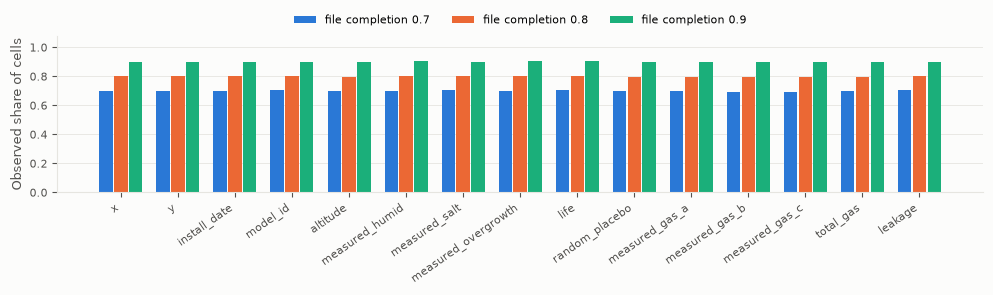

In [3]:
FILE_AUDIT = audit_files(ALL_SCENARIOS)
FIELD_AUDIT = audit_fields(ALL_SCENARIOS)
display(FILE_AUDIT.round(4))
fg.plot_missingness(FIELD_AUDIT, None)

In [4]:
noise_check = FIELD_AUDIT.groupby(["column", "noise"], sort=False).agg(
    changed=("changed share", "mean"),
    largest=("largest relative change", "max"),
    measurement_mae=("measurement MAE", "mean"),
).unstack("noise")
display(noise_check.round(4))

noise_free = FIELD_AUDIT[FIELD_AUDIT.noise.eq(0)]
inside_bound = (FIELD_AUDIT["largest relative change"] <= FIELD_AUDIT.noise + 1e-9).all()
never_noisy = FIELD_AUDIT[~FIELD_AUDIT["defined as noisy"]]["changed share"].eq(0).all()
print("Noise-free files equal the truth in every observed cell:", noise_free["changed share"].eq(0).all())
print("Every measured value lies inside the bound in its file name:", inside_bound)
print("Columns defined without noise are unchanged in every file:", never_noisy)

changed                 largest            measurement_mae                    
noise                  0.00    0.05    0.10    0.00  0.05 0.10            0.00      0.05      0.10
column                                                                                            
x                       0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
y                       0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
install_date            0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
model_id                0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
altitude                0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
measured_humid          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0    0.0083    0.0166
measured_salt           0.0  1.0000  1.0000     0.0  0.05  0.1             0.0    0.0104    0.0208
measured_overgrowth     0.0  0.6773  0.6773     0.0  0.05  0.1             0.0    0.0083    0.0167
life                    0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
random_placebo          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0    0.0125    0.0251
measured_gas_a          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0  233.2870  466.5740
measured_gas_b          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0  243.3178  486.6355
measured_gas_c          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0  233.6805  467.3610
total_gas               0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
leakage                 0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000

Noise-free files equal the truth in every observed cell: True
Every measured value lies inside the bound in its file name: True
Columns defined without noise are unchanged in every file: True


The next cell confirms two things: scenarios can be compared cell by cell, and the truth follows the generator's definitions.

In [5]:
with pd.option_context("display.max_colwidth", None):
    display(audit_design(ALL_SCENARIOS))
display(relationship_residuals(read_truth(ALL_SCENARIOS[REPRESENTATIVE])))

,property,holds
0,Every file has the same truth,True
1,A completeness level hides the same cells at every noise level,True
2,Cells hidden at higher completeness are also hidden at lower completeness,True


,definition,largest residual
0,altitude = x + y + 100,0.000000e+00
1,"overgrowth = max(2 humid - salt, 0)",4.440892e-16
2,total_gas = gas a + b + c,1.273293e-11
3,life follows the formula of the row's model,4.365575e-11


### 2.4 Generator decisions

The dataset was regenerated after review with the generator's author. The earlier version is kept in `data/datasets_v1`.

- **Masking** covers all 15 columns. The first version covered only the first eight.
- **Noise** applies only to humidity, salt, overgrowth, the placebo and the three gas readings. `life`, `total_gas` and `leakage` are exact by design, so some columns stay reliable when others degrade.
- **Gas and `life`**: more gas reduces `life` for every model. The scale `total_gas/300000` is kept from the first version, so this term is small.
- **Model 0** uses `day_count` in its overgrowth term, matching the other models. The first version used an undefined variable.
- **Missingness** is completely at random only. The generator does not explore other mechanisms.

### 2.5 Other ways cells can go missing

The generator hides every cell with the same chance. Gaps in real asset data often depend on the asset, so two more scenarios are built from the generator's own files. Each hides the same overall share of cells as the representative scenario, and differs only in which cells are hidden:

- **age**: older assets lose more cells.
- **value**: higher values are hidden more often, in every numeric column.

They are built from the file with 0.9 completion by hiding further cells, so every visible cell keeps the value the generator wrote. The table shows the hidden share in each age third and in the lowest and highest fifth of `life`.

In [6]:
rows = []
age_third = pd.qcut(read_truth(ALL_SCENARIOS[REPRESENTATIVE]).install_date.rank(method="first"), 3,
                    labels=["oldest third", "middle third", "newest third"])
life = read_truth(ALL_SCENARIOS[REPRESENTATIVE]).life
for name, frame in {REPRESENTATIVE: STUDY.measured[REPRESENTATIVE], **{n: STUDY.measured[n] for n in STUDY.mechanisms}}.items():
    hidden = frame.isna()
    by_age = hidden.mean(axis=1).groupby(age_third.reindex(frame.index), observed=True).mean()
    rows.append({"scenario": name, "mechanism": STUDY.scenarios[name].mechanism, "hidden share": hidden.to_numpy().mean(),
                 **by_age.to_dict(), "life: lowest fifth": hidden.life[life.reindex(frame.index) <= life.quantile(0.2)].mean(),
                 "life: highest fifth": hidden.life[life.reindex(frame.index) >= life.quantile(0.8)].mean()})
display(pd.DataFrame(rows).round(3))
for name, text in DESCRIPTIONS.items():
    print(f"{name}: {text}")

,scenario,mechanism,hidden share,oldest third,middle third,newest third,life: lowest fifth,life: highest fifth
0,completion0.8-noise0.05,random,0.200,0.201,0.201,0.197,0.194,0.204
1,completion0.8-noise0.05-age,age,0.199,0.266,0.200,0.131,0.149,0.176
2,completion0.8-noise0.05-value,value,0.199,0.197,0.199,0.202,0.112,0.280


age: Older assets lose more cells: the hidden share falls from 30% for the oldest row to 10% for the newest.
value: Higher values are hidden more often: the hidden share rises from 10% for the lowest value of a column to 30% for the highest. model_id is nominal and is hidden at random.


## 3. Experimental design

### 3.1 Targets and predictors

Every column has missing cells, so all 15 are imputation targets: 14 numeric columns and `model_id`. `random_placebo` is one of them and serves as the negative control: it is unrelated to every other column, so no model should predict it better than the median. For each target, every other column is a predictor.

### 3.2 Preprocessing

All fitted values, including means, scales and category levels, come from the training fold.

| Step | Decision | Reason |
|---|---|---|
| Missing predictors | Left as missing at the start | Each method handles gaps natively, so no fixed value is invented. Chained models then replace gaps with their own estimates. |
| Missing indicators | Not used | In the generator's files masks are random, so an indicator carries no information about the value. |
| `model_id` as a predictor | One-hot for distance and linear models; a category or number for trees | It is nominal, so distances and coefficients must not read its numbers as an order. Trees can split it into its levels. |
| Row position | Never a feature | It would reveal the grid position, and it is not a property of an asset. |
| Predictions | Limited to the valid range; whole-number columns rounded | This follows from the column definitions. The raw value is kept, and section 7.2 reports how often this applied. |

### 3.3 Choosing settings

Every setting was chosen before this study, from a fixed list of candidates, by a rule fixed before the candidates were scored. Settings then stay the same in every scenario, so a change between scenarios is not caused by a change of settings.

- **Data:** the three scenarios at 0.7 completion. Masks are nested, so a cell visible there is visible in every scenario. No cell hidden in any scenario is read, and truth files are not read.
- **Score:** a further 10% of observed cells is hidden, and error on those cells is compared with the median's error. `random_placebo` is left out of the score.
- **Choice:** candidates more than 1% worse than the median on `random_placebo` are dropped. Of the rest, those within 0.002 of the best score are kept, and the fastest is chosen.

Candidates included each model with no ridge base and with a straight-line base, and every chained model was offered the same range of passes. The second-order base scored best for every model. The rule and all scores are kept in `outputs/imputation-study/optimisation/clean_selection`. Section 7.6 measures the effect of the base again, against the truth.

### 3.4 Evaluation

Five folds are shared by all methods within a seed. A hidden cell is predicted by a model that never saw its row, and it is scored against the truth.

| Measure | Used for |
|---|---|
| MAE, RMSE, R², bias | Size and direction of error, in the column's own unit |
| Skill | Share of the baseline's error removed on the same cells: 0 matches the baseline, 1 is perfect, below 0 is worse. The baseline is the median, or the mode for `model_id` |
| Tolerance rate | Share within the column's tight and loose limits from section 2.2 |
| Exact rate | Share of whole-number columns recovered exactly |
| Accuracy, macro F1, balanced accuracy | `model_id`; log loss, Brier score and calibration gap for its probabilities |

MAE values are never averaged across columns because their units differ. Skill has no unit, so it is the measure used to compare columns and conditions. Section 5.1 sets the standard for failure in terms of skill.

### 3.5 Experiments

The next cell lists the planned tasks. The experiments are described below the table.

In [7]:
display(plan_table(STUDY.plan))
print("Planned tasks:", len(STUDY.plan))

,experiment,tasks,scenarios,seeds,methods
0,main,945,9,1,8
1,stability,210,1,2,8
2,budget,10,1,1,2
3,structure,20,1,1,4
4,calibration,10,1,1,1
5,ablation,375,3,1,5
6,importance,450,3,1,2
7,mechanism,210,2,1,8


Planned tasks: 2230


- **main**: every method in each of the nine generator scenarios. A chained method is one task per fold, covering all its columns.
- **stability**: the representative scenario with two more fold seeds.
- **budget**: IterativeImputer at other pass limits, showing the effect of the number of passes.
- **structure**: the chained models refitted with no ridge base, in the representative scenario. This measures what the shared base adds.
- **calibration**: the same forest with calibrated probabilities for `model_id`, with all predictors and without the gas columns.
- **ablation**: refits without a block of predictors, across the three noise levels at 0.8 completion. Targets inside the removed block are skipped.
- **importance**: permutation importance on held-out observed labels, from single-target forest and CatBoost models on all five folds, because a chain covers every column at once.
- **mechanism**: every method in the two scenarios of section 2.5, where cells are not hidden completely at random.

## 4. Models

This chapter fits the models. When `EVALUATION_RUN_ID` is set, each section loads saved results in place of fitting. Each model has its own section with a short description, its setup, then its run and results. Sections run in order, starting with the baselines, because skill is measured against the median. Finished tasks are saved immediately, so an interruption loses only the tasks in progress. Model code never reads truth. Unless stated otherwise, tables show the representative scenario, `completion0.8-noise0.05`, which has moderate missingness and moderate noise.

**How the chained models work.** Sections 4.2 and 4.4 to 4.6 use chained imputation with a ridge base:

1. The first pass predicts each column in turn from the others, starting from the original gaps. Each prediction is filled in straight away, so the next column can use it.
2. Later passes repeat this with the latest estimates, so every row is now complete.
3. In later passes, a ridge regression on the other columns and their second-order terms takes the smooth part of each column. Second-order terms are squares and pairwise products.
4. The local model (trees or neighbours) fits only what the ridge leaves. The prediction is the sum of the two.

A chain lets a hidden cell use estimates of the other hidden cells in its row. The ridge handles sums, which trees and neighbours can only approximate with many small steps. The local model handles thresholds and interactions. One fit covers every column, so settings are shared by all columns.

Four models therefore share most of their structure. Two sections act as references for it: section 4.3 uses the ridge alone, and section 4.7 uses a boosted chain with no ridge. Section 7.6 compares them.

Where a model reports `model_id`, the value comes from a separate classifier on the original gaps, because a filled-in estimate looks as certain as a measurement. Section 3.3 explains how all settings were chosen.

### 4.1 Median and Mode

The baselines fill every hidden cell with one value from the training fold: the median for numeric targets and the most common class for `model_id`. They use no other column, so they cannot learn any relationship.

**Reading the results:** every other model needs to beat these to show that it has learned something. On `random_placebo`, the median is the correct answer.

In [8]:
STUDY.run_model("Median and Mode")
STUDY.show_model("Median and Mode")

Median and Mode: loaded 975 saved tasks


**Median · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,24.8884,28.7428,-0.0006,0.1658,0.0,0.0302,0.1085,0.0116
1,y,25.3187,29.0652,-0.0009,0.0348,0.0,0.0268,0.1010,0.0071
2,install_date,343.3320,397.3921,-0.0005,3.2955,0.0,0.0127,0.0471,0.0010
3,altitude,33.8737,41.2782,-0.0022,1.8260,0.0,0.0269,0.0930,0.0094
4,measured_humid,0.1730,0.2083,-0.0066,-0.0169,0.0,0.1048,0.1562,NaN
5,measured_salt,0.2117,0.2475,-0.0022,-0.0116,0.0,0.1029,0.1501,NaN
6,measured_overgrowth,0.3008,0.3821,-0.0954,-0.1128,0.0,0.0467,0.0720,NaN
7,life,290.0439,392.9534,-0.0423,79.0972,0.0,0.2329,0.8304,NaN
8,random_placebo,0.2530,0.2911,-0.0021,0.0126,0.0,0.1034,0.1502,NaN
9,measured_gas_a,1247.7975,1450.9424,-0.0505,-317.5190,0.0,0.0597,0.3916,NaN


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
4,Mode,1965,0.2809,0.1774,0.2483


,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,Median,630,5.732,0.754,0.010
1,Mode,45,0.481,0.052,0.012


Tasks: 975 | failed: 0 | with warnings: 0


### 4.2 K-nearest neighbours

KNN finds the rows most similar to the one being filled and averages their values. It assumes nothing about the form of a relationship, but it needs similar rows to exist.

**Setup:** six passes with the ridge base, using 80 neighbours weighted by distance. Columns are scaled so that no unit dominates the distance. The first pass compares only the cells two rows share; later passes compare complete rows. `model_id` enters as one-hot columns.

**Reading the results:** section 7.6 shows how much of the result comes from the ridge base and how much from the neighbours. Every column counts equally in the distance, including unrelated ones such as `random_placebo`.

KNN: loaded 145 saved tasks


**KNN imputer · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,0.6824,1.7911,0.9961,0.0603,0.9726,0.9106,0.9774,0.6191
1,y,4.8480,12.1888,0.8240,-0.6116,0.8085,0.7848,0.8207,0.5702
2,install_date,10.6929,24.8126,0.9961,0.2985,0.9689,0.6432,0.9377,0.0390
3,altitude,4.6932,12.0311,0.9149,-0.5619,0.8615,0.7822,0.8215,0.6256
4,measured_humid,0.0527,0.0824,0.8426,-0.0061,0.6956,0.4869,0.5680,NaN
5,measured_salt,0.1020,0.1464,0.6492,0.0036,0.5182,0.3408,0.4493,NaN
6,measured_overgrowth,0.0506,0.1053,0.9169,-0.0086,0.8317,0.6077,0.6920,NaN
7,life,42.8900,92.0560,0.9428,2.4396,0.8521,0.9285,0.9908,NaN
8,random_placebo,0.2565,0.2955,-0.0328,0.0119,-0.0138,0.0965,0.1487,NaN
9,measured_gas_a,151.5550,331.6535,0.9451,-3.0182,0.8785,0.9843,0.9863,NaN


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
9,KNN imputer,1965,0.9781,0.9771,0.9773


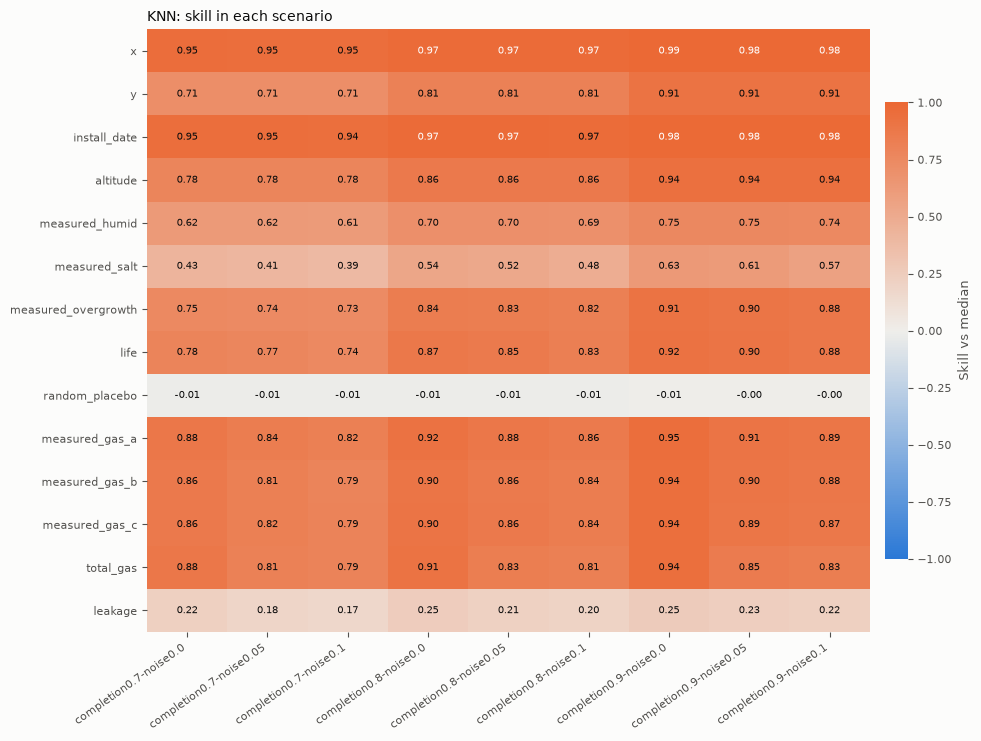

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
KNN imputer,0.9414,0.936,0.8966,0.9832,0.9781,0.945,0.997,0.996,0.9698


,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,KNN imputer,45,5242.219,6637.495,17.6


Tasks: 145 | failed: 0 | with warnings: 0


In [9]:
STUDY.run_model("KNN")
STUDY.show_model("KNN")

### 4.3 IterativeImputer

IterativeImputer fills each column from the others and repeats. Here it uses only the ridge, with no local model, and covers the numeric columns.

**Setup:** ten passes on scaled columns. Straight-line terms have a penalty of 30 and second-order terms a penalty of 1,000, because the many second-order terms need a stronger penalty. Without a penalty, near-duplicate columns such as `altitude` and `x + y + 100` make the chain unstable. `model_id` enters as one-hot columns that stay empty when it is missing, so the chain estimates them too. Every estimate stays inside its column's observed training range, because squared terms otherwise feed on their own estimates and diverge.

**Reading the results:** the penalties trade exact recovery of sums for stability, so exact sums are the place to look for their cost. Second-order terms are what allow this model to represent `life` and the overgrowth threshold.

IterativeImputer: loaded 150 saved tasks


**IterativeImputer · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,0.7482,1.9776,0.9953,0.0839,0.9699,0.9060,0.9794,0.5894
1,y,5.5323,13.9731,0.7687,-0.1798,0.7815,0.7778,0.8202,0.4904
2,install_date,11.3670,27.3045,0.9953,0.6057,0.9669,0.6158,0.9351,0.0380
3,altitude,5.3307,13.8548,0.8871,-0.1323,0.8426,0.7802,0.8235,0.5932
4,measured_humid,0.0583,0.0863,0.8273,-0.0057,0.6633,0.4370,0.5267,NaN
5,measured_salt,0.1132,0.1600,0.5811,0.0086,0.4655,0.3022,0.4148,NaN
6,measured_overgrowth,0.0584,0.1121,0.9058,-0.0076,0.8059,0.5594,0.6352,NaN
7,life,56.7300,102.6477,0.9289,4.7620,0.8044,0.8749,0.9918,NaN
8,random_placebo,0.2544,0.2925,-0.0122,0.0122,-0.0056,0.0980,0.1512,NaN
9,measured_gas_a,166.0035,295.5291,0.9564,-11.7370,0.8670,0.9501,0.9775,NaN


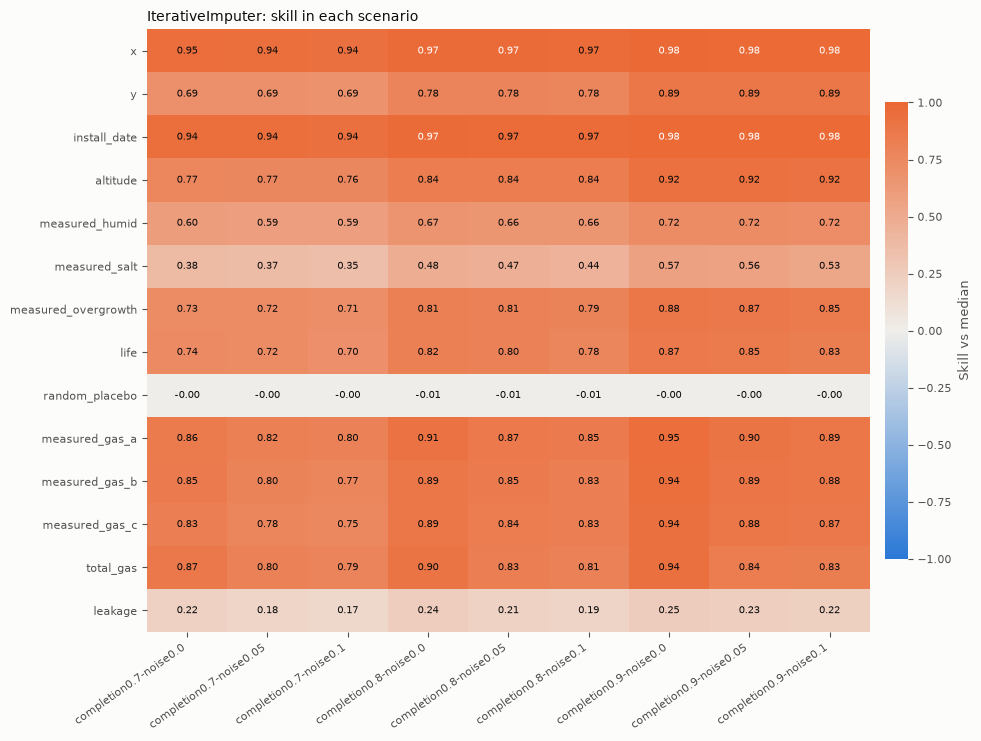

,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,IterativeImputer,45,383.279,6.931,0.619


Tasks: 150 | failed: 0 | with warnings: 150


In [10]:
STUDY.run_model("IterativeImputer")
STUDY.show_model("IterativeImputer")

**Number of passes.** The first table shows MAE on the same cells at other pass limits. The second shows the passes used in each scenario. A fit that stops at the limit has not converged, which is intended here. Ten passes gave the best overall score when the settings were chosen.

In [11]:
iterative_numeric, _ = STUDY.scores_for("IterativeImputer")
budget, iterations = ev.budget_table(iterative_numeric, STUDY.logs["IterativeImputer"], STUDY.config)
display(budget.round(4))
display(iterations)

,MAE at limit 5,MAE at limit 10,MAE at limit 30
target,,,
x,0.9276,0.7482,0.6854
y,5.6929,5.5323,5.1944
install_date,14.0826,11.3670,10.5342
altitude,5.5206,5.3307,4.9871
measured_humid,0.0572,0.0583,0.0610
measured_salt,0.1113,0.1132,0.1184
measured_overgrowth,0.0586,0.0584,0.0605
life,57.1631,56.7300,57.6034
random_placebo,0.2544,0.2544,0.2544


,scenario,fits,fewest iterations,most iterations,fits stopped at the limit
0,completion0.7-noise0.0,5,10,10,5
1,completion0.7-noise0.05,5,10,10,5
2,completion0.7-noise0.1,5,10,10,5
3,completion0.8-noise0.0,5,10,10,5
4,completion0.8-noise0.05,5,10,10,5
5,completion0.8-noise0.1,5,10,10,5
6,completion0.9-noise0.0,5,10,10,5
7,completion0.9-noise0.05,5,10,10,5
8,completion0.9-noise0.1,5,10,10,5


### 4.4 Random Forest

Random Forest averages many decision trees, each grown on a sample of the rows. Averaging reduces the noise of single trees, and trees capture thresholds and interactions without being told about them. Run as a chain, it follows the style of MissForest.

**Setup:** four passes with the ridge base. Each column uses 100 trees grown on half of the rows, with at least two rows per leaf. Trees need no scaling and handle the gaps of the first pass themselves. `model_id` enters as a number, which trees can split into its four levels.

**Reading the results:** a forest alone cannot predict outside the range of its training labels. The ridge base can, which helps with sums such as `altitude`.

Random Forest: loaded 380 saved tasks


**Random Forest · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,0.5744,1.8874,0.9957,0.0709,0.9769,0.9045,0.9784,0.7563
1,y,4.6369,11.9633,0.8304,-0.4500,0.8169,0.7843,0.8192,0.6747
2,install_date,9.5565,26.4563,0.9956,0.7354,0.9722,0.7775,0.9341,0.0907
3,altitude,4.5540,11.8359,0.9176,-0.3879,0.8656,0.7797,0.8215,0.6793
4,measured_humid,0.0428,0.0726,0.8778,-0.0001,0.7526,0.5897,0.6447,NaN
5,measured_salt,0.0894,0.1374,0.6913,-0.0017,0.5779,0.4173,0.5127,NaN
6,measured_overgrowth,0.0474,0.1013,0.9230,-0.0032,0.8426,0.6628,0.7218,NaN
7,life,35.9675,83.4695,0.9530,-0.4101,0.8760,0.9428,0.9928,NaN
8,random_placebo,0.2575,0.2975,-0.0468,0.0127,-0.0175,0.0980,0.1537,NaN
9,measured_gas_a,141.2617,307.0163,0.9530,-3.6194,0.8868,0.9883,0.9897,NaN


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
2,Random Forest,1965,0.9786,0.9774,0.9763


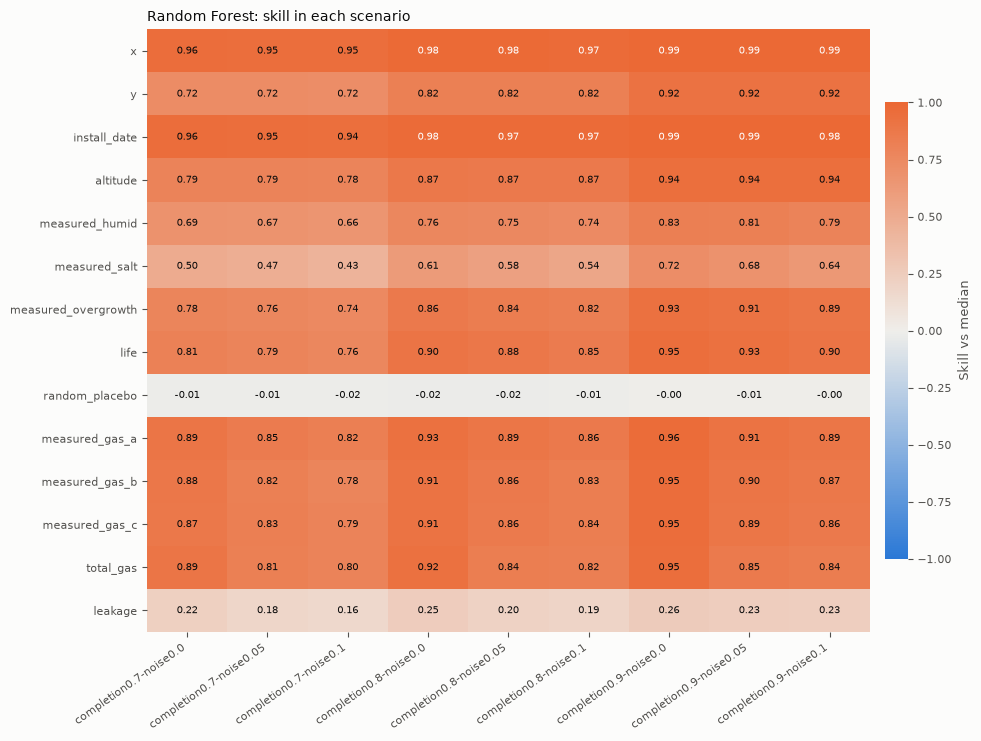

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
Random Forest,0.9693,0.9673,0.937,0.9827,0.9786,0.9588,0.999,0.999,0.9779


,method,tasks,fit seconds,predict seconds,seconds per target and fold
2,Random Forest,45,5175.787,68.083,7.769


Tasks: 380 | failed: 0 | with warnings: 0


In [12]:
STUDY.run_model("Random Forest")
STUDY.show_model("Random Forest")

**Calibrated probabilities for `model_id`.** A confident prediction should be correct about as often as its probability says, and the calibration gap measures the difference. The comparison is repeated without the gas columns, because the task is otherwise too easy to separate the methods. The calibrated model uses the same forest settings as the raw result. It trains on inner folds, so it sees fewer rows for each fit.

In [13]:
display(ev.probability_table(STUDY.scored["Random Forest"], STUDY.config).round(4))

,predictors,method,n,accuracy,log loss,Brier,calibration gap,accuracy of most confident 50%
0,all predictors,Random Forest calibrated,1965,0.9807,0.0457,0.0257,0.0147,1.0000
2,all predictors,Random Forest,1965,0.9786,0.0844,0.0318,0.0468,1.0000
1,without gas columns,Random Forest calibrated,1965,0.7522,0.5654,0.3279,0.0399,0.9420
3,without gas columns,Random Forest,1965,0.7420,0.5825,0.3385,0.0857,0.9511


### 4.5 HistGradientBoosting

Gradient boosting builds trees one after another, each fitted to the error the earlier trees left. HistGradientBoosting first groups each column into bins, which makes it fast on data of this size.

**Setup:** six passes with the ridge base, using trees of up to 31 leaves. In the first pass, each split learns which side missing values should go to. Each regressor stops adding trees when error on 15% held-out rows stops falling, so a column with no signal gets few trees. `model_id` is a native categorical input.

**Reading the results:** boosting can fit fine detail, so it can also fit noise. The result on `random_placebo` shows how far that goes.

HistGradientBoosting: loaded 145 saved tasks


**HistGradientBoosting · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,0.3874,1.8284,0.9960,0.0367,0.9844,0.9432,0.9849,0.8573
1,y,4.5854,12.0340,0.8284,-0.3247,0.8189,0.7884,0.8212,0.7566
2,install_date,7.1764,25.6273,0.9958,0.3350,0.9791,0.8550,0.9595,0.1237
3,altitude,4.5122,11.9163,0.9165,-0.3053,0.8668,0.7837,0.8225,0.7499
4,measured_humid,0.0432,0.0742,0.8722,-0.0015,0.7506,0.5837,0.6537,NaN
5,measured_salt,0.0887,0.1386,0.6859,0.0000,0.5811,0.4189,0.5147,NaN
6,measured_overgrowth,0.0457,0.1005,0.9243,-0.0016,0.8481,0.6697,0.7318,NaN
7,life,35.3523,85.2026,0.9510,-0.1550,0.8781,0.9433,0.9923,NaN
8,random_placebo,0.2552,0.2938,-0.0206,0.0121,-0.0086,0.0970,0.1477,NaN
9,measured_gas_a,150.9021,352.4413,0.9380,-0.2638,0.8791,0.9838,0.9843,NaN


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
9,HistGradientBoosting,1965,0.9807,0.9794,0.9794


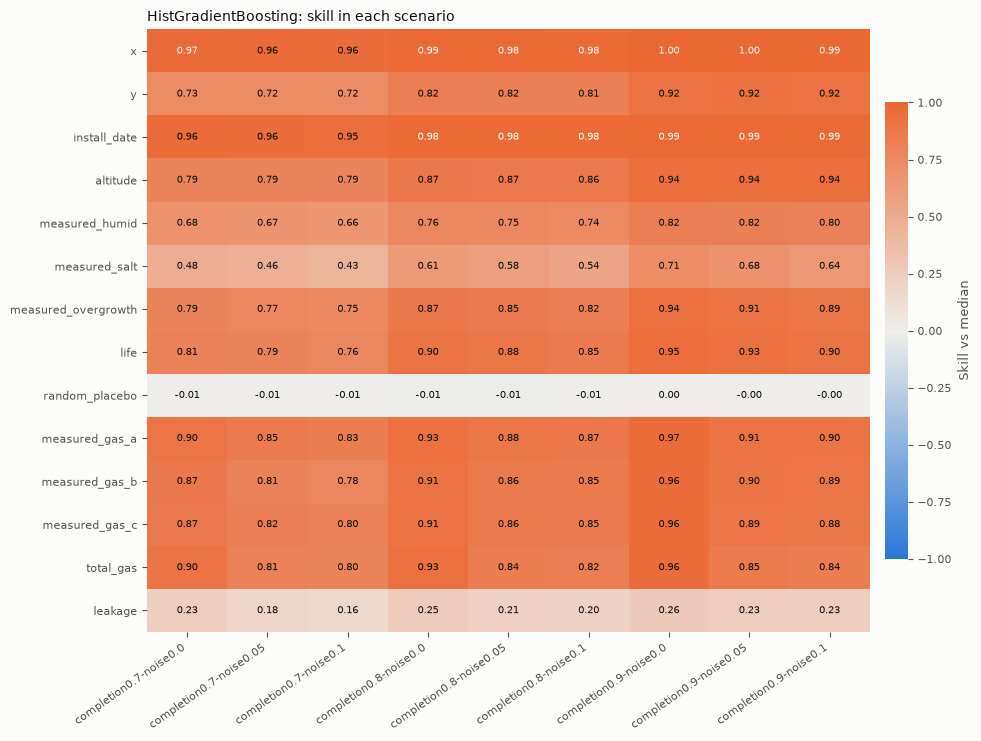

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
HistGradientBoosting,0.9693,0.9666,0.9441,0.9842,0.9807,0.9654,0.999,0.998,0.9869


,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,HistGradientBoosting,45,2176.999,105.846,3.382


Tasks: 145 | failed: 0 | with warnings: 0


In [14]:
STUDY.run_model("HistGradientBoosting")
STUDY.show_model("HistGradientBoosting")

### 4.6 CatBoost

CatBoost is gradient boosting on symmetric trees, where every node at a given depth uses the same split. This acts as built-in regularisation.

**Setup:** six passes with the ridge base, using trees of depth four. Each regressor stops adding trees when error on 15% held-out rows has not improved for 30 rounds. Gaps in the first pass are handled natively. `model_id` enters as a number.

**Reading the results:** comparing this section with section 4.5 shows the effect of CatBoost's stronger regularisation on noisy targets.

CatBoost: loaded 370 saved tasks


**CatBoost · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,0.4186,1.9269,0.9955,0.0397,0.9832,0.9422,0.9794,0.8613
1,y,4.5313,11.8951,0.8324,-0.3919,0.8210,0.7884,0.8212,0.7621
2,install_date,7.5231,27.0784,0.9954,0.4881,0.9781,0.8702,0.9549,0.1277
3,altitude,4.4346,11.7812,0.9184,-0.3471,0.8691,0.7872,0.8265,0.7633
4,measured_humid,0.0436,0.0726,0.8778,-0.0019,0.7483,0.5766,0.6366,NaN
5,measured_salt,0.0927,0.1416,0.6719,-0.0007,0.5623,0.3864,0.4970,NaN
6,measured_overgrowth,0.0457,0.0994,0.9259,-0.0013,0.8479,0.6598,0.7387,NaN
7,life,35.8383,83.6171,0.9528,-2.5886,0.8764,0.9402,0.9928,NaN
8,random_placebo,0.2546,0.2930,-0.0157,0.0122,-0.0063,0.0975,0.1507,NaN
9,measured_gas_a,151.2448,351.6281,0.9383,8.4428,0.8788,0.9848,0.9858,NaN


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
3,CatBoost,1965,0.9791,0.9778,0.9778


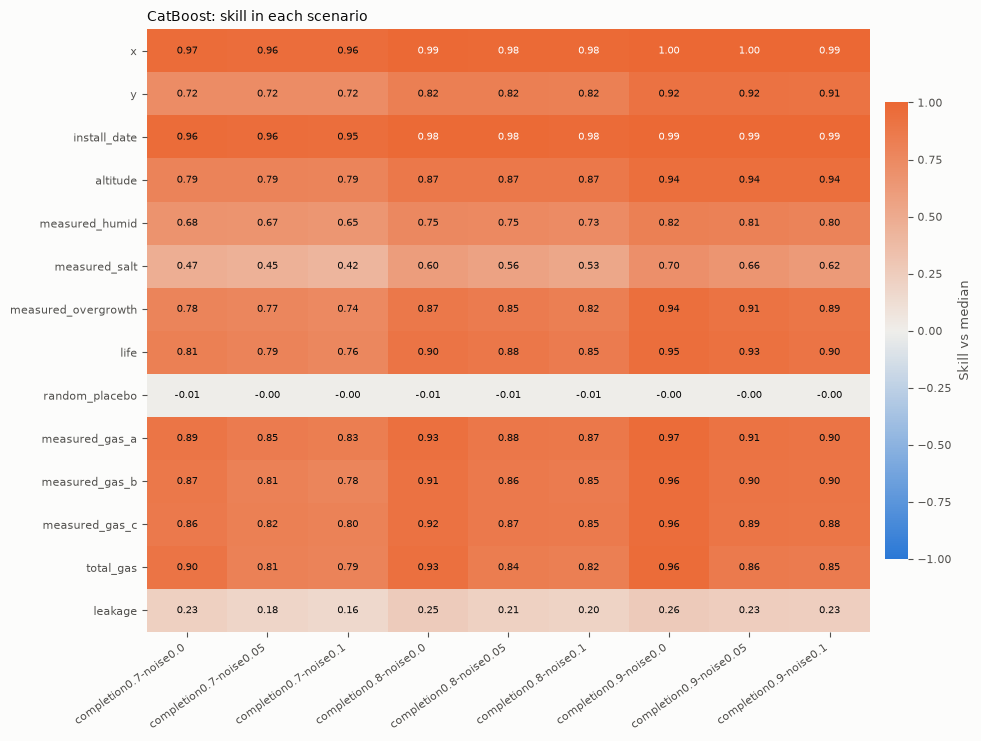

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
CatBoost,0.9666,0.9626,0.935,0.9837,0.9791,0.9598,0.999,0.999,0.9839


,method,tasks,fit seconds,predict seconds,seconds per target and fold
1,CatBoost,45,4628.046,14.708,6.878


Tasks: 370 | failed: 0 | with warnings: 0


In [15]:
STUDY.run_model("CatBoost")
STUDY.show_model("CatBoost")

### 4.7 miceforest direct

miceforest runs chained equations with LightGBM, another gradient boosting library. This section uses the model's predictions directly, without donor matching and without the ridge base. The project's audited compatibility patch for miceforest 6.0.5 is used throughout.

**Setup:** three passes of 200 boosting rounds, with each tree seeing 70% of the columns. miceforest's defaults are changed in two ways. It normally starts from random values, which would feed the first models with noise, so here it starts from the gaps. It also normally runs a depth-limited random forest that ignores the learning rate, so here it runs true gradient boosting.

**Reading the results:** this model shares nothing with the ridge base of the other chained models, so it shows what a boosted chain reaches without it.

miceforest direct: loaded 65 saved tasks


**miceforest direct · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,1.1643,2.6869,0.9913,0.1492,0.9532,0.8271,0.9417,0.5452
1,y,5.4485,11.9258,0.8315,-0.4030,0.7848,0.5197,0.8162,0.2020
2,install_date,17.5058,38.8466,0.9904,0.7577,0.9490,0.5884,0.8642,0.0578
3,altitude,5.1308,11.6613,0.9200,-0.1641,0.8485,0.6315,0.8180,0.2576
4,measured_humid,0.0481,0.0758,0.8667,0.0009,0.7217,0.5353,0.6124,NaN
5,measured_salt,0.0954,0.1413,0.6736,0.0041,0.5493,0.3864,0.4944,NaN
6,measured_overgrowth,0.0562,0.1080,0.9125,0.0040,0.8132,0.5747,0.6613,NaN
7,life,44.3172,88.4735,0.9472,-0.2024,0.8472,0.9127,0.9934,NaN
8,random_placebo,0.2557,0.2959,-0.0355,0.0127,-0.0105,0.1064,0.1492,NaN
9,measured_gas_a,143.1308,277.8758,0.9615,-17.6410,0.8853,0.9824,0.9863,NaN


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
4,miceforest direct,1965,0.9837,0.9827,0.9828


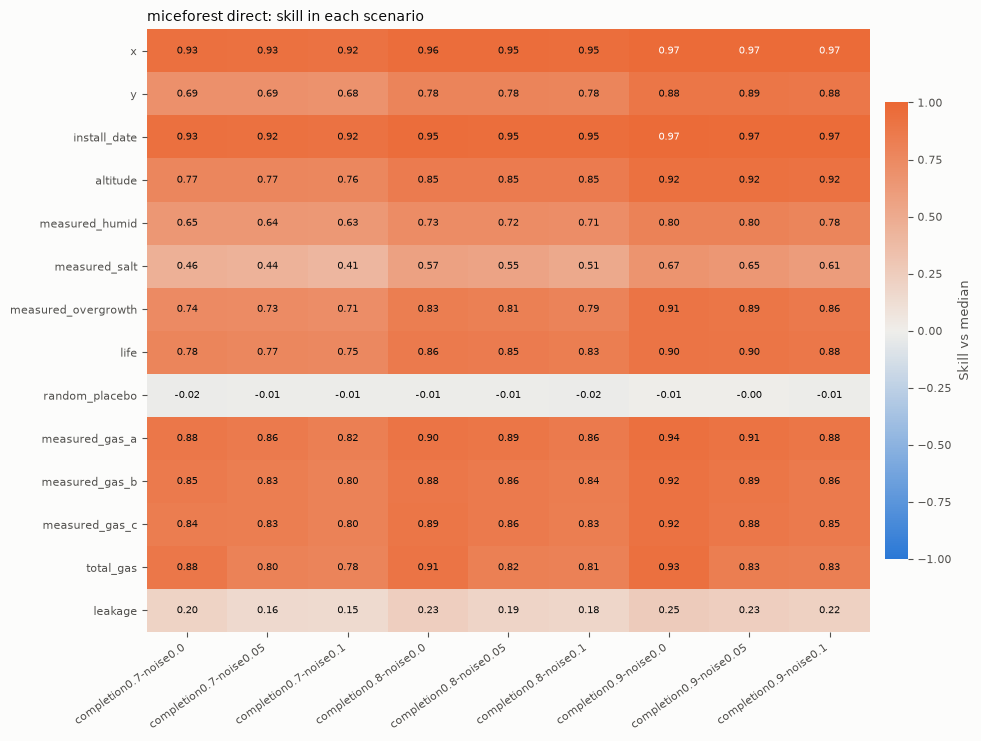

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
miceforest direct,0.9683,0.967,0.9434,0.9842,0.9837,0.9659,0.999,0.997,0.9849


,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,miceforest direct,45,496.553,24.659,0.772


Tasks: 65 | failed: 0 | with warnings: 0


In [16]:
STUDY.run_model("miceforest direct")
STUDY.show_model("miceforest direct")

## 5. Overview

**The evaluation starts here.** Chapters 5 to 9 and the appendix need only the setup cell and a finished run. They use saved predictions and fit no model, so they can be repeated quickly after any change to the evaluation code.

The next cell collects all results. Three models are followed in detail: CatBoost, Random Forest and KNN. They share the ridge base and differ in the local model that corrects it. IterativeImputer and miceforest direct are shown as references, the first for the ridge alone and the second for a chain with no ridge. HistGradientBoosting is the same kind of model as CatBoost, so it appears in the appendix. The baseline is part of every comparison.

In [17]:
STUDY.finish()
NUMERIC, CATEGORY, PAIRS, CELLS = STUDY.numeric, STUDY.category, STUDY.pairs, STUDY.cells
SCORED, FIGURES = STUDY.all_scored, STUDY.figures
MAIN, SHOWN, LEAD = list(fl.MAIN_METHODS), list(fl.SHOWN_METHODS), fl.LEAD_METHOD
display(ev.run_summary(STUDY.log, STUDY.plan))
print("Models followed in detail:", ", ".join(MAIN), "| references:", ", ".join(fl.REFERENCE_METHODS), "| lead model:", LEAD)

,planned tasks,finished tasks,succeeded,failed,tasks with warnings
0,2230,2230,2230,0,150


Models followed in detail: CatBoost, Random Forest, KNN imputer | references: IterativeImputer, miceforest direct | lead model: CatBoost


### 5.1 The standard for failure

A model is judged by its skill: the share of the baseline's error it removes on the same cells.

| State | Skill | Meaning |
|---|---|---|
| works | 0.5 or more | The model removes at least half of the baseline's error |
| weak | 0.1 to 0.5 | It removes less than half |
| fails | below 0.1 | It adds almost nothing to the baseline |

The tolerance limits of section 2.2 are not used as the standard, because the share of cells inside a limit depends on how wide a column's range is, and a baseline can already meet a limit on a narrow column. Skill includes the baseline by definition. The table shows both measures side by side, for the lead model and the baseline, so that the two can be compared.

In [18]:
standard = fl.skill_by(fl.main_cells(CELLS, STUDY.config, REPRESENTATIVE), ["target", "method"])
standard = standard[standard.method.isin(["Median", LEAD]) & standard.target.ne("model_id")]
table = standard.pivot(index="target", columns="method", values="within").reindex(list(NUMERIC_TARGETS))
table.columns = [f"share within loose tolerance: {c}" for c in table.columns]
table[f"skill: {LEAD}"] = standard[standard.method.eq(LEAD)].set_index("target").skill
display(table.round(3))

,share within loose tolerance: CatBoost,share within loose tolerance: Median,skill: CatBoost
target,,,
x,0.979,0.109,0.983
y,0.821,0.101,0.821
install_date,0.955,0.047,0.978
altitude,0.826,0.093,0.869
measured_humid,0.637,0.156,0.748
measured_salt,0.497,0.150,0.562
measured_overgrowth,0.739,0.072,0.848
life,0.993,0.830,0.876
random_placebo,0.151,0.150,-0.006


### 5.2 Overall level

The chart shows skill in the representative scenario for the three main models and the two references. Columns are grouped by the kind of relationship that defines them. The shaded band is the failing range, and the vertical line is the baseline.

The table adds the baseline's own error, in the column's unit, and the remaining model.

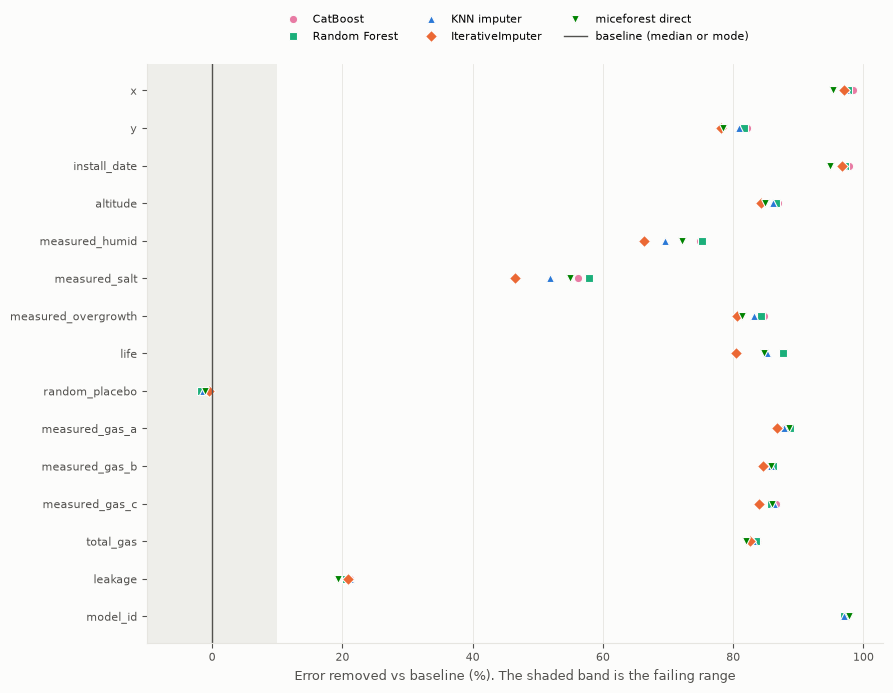

method,kind of relationship,baseline error,CatBoost,Random Forest,KNN imputer,IterativeImputer,miceforest direct,HistGradientBoosting
target,,,,,,,,
x,near copy of another column,24.888,0.983,0.977,0.973,0.970,0.953,0.984
y,exact sum,25.319,0.821,0.817,0.809,0.781,0.785,0.819
install_date,near copy of another column,343.332,0.978,0.972,0.969,0.967,0.949,0.979
altitude,exact sum,33.874,0.869,0.866,0.861,0.843,0.849,0.867
measured_humid,random draw scaled by another column,0.173,0.748,0.753,0.696,0.663,0.722,0.751
measured_salt,random draw scaled by another column,0.212,0.562,0.578,0.518,0.466,0.549,0.581
measured_overgrowth,threshold,0.301,0.848,0.843,0.832,0.806,0.813,0.848
life,product that depends on the model,290.044,0.876,0.876,0.852,0.804,0.847,0.878
random_placebo,no relationship,0.253,-0.006,-0.018,-0.014,-0.006,-0.010,-0.009


In [19]:
fg.plot_overall(STUDY.overall, SHOWN, FIGURES)
with pd.option_context("display.max_colwidth", 60):
    display(STUDY.overall.round(3))

### 5.3 Map of every condition

Each column of the map changes one thing against the reference scenario. Values are the skill of the lead model, and bold values are below 0.5. The second table gives the state of each cell under the standard of section 5.1.

- **highest noise**, **lowest completion**, **both together**: other generator scenarios.
- **few linked columns visible**: cells of the reference scenario in which at most a third of the directly linked columns were visible in the row.
- **older assets hidden more**, **higher values hidden more**: the scenarios of section 2.5.
- **most harmful block removed**: the lowest skill after one block of predictors is removed and the model is refitted.

Chapters 6 to 8 take these conditions one at a time.

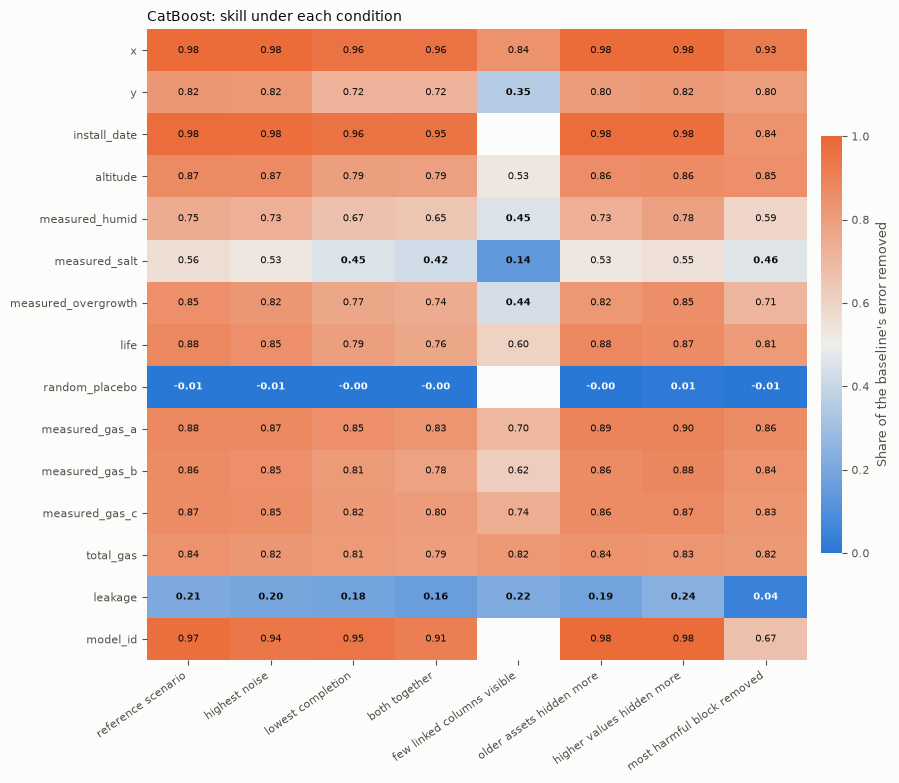

,reference scenario,highest noise,lowest completion,both together,few linked columns visible,older assets hidden more,higher values hidden more,most harmful block removed
target,,,,,,,,
x,works,works,works,works,works,works,works,works
y,works,works,works,works,weak,works,works,works
install_date,works,works,works,works,not measured,works,works,works
altitude,works,works,works,works,works,works,works,works
measured_humid,works,works,works,works,weak,works,works,works
measured_salt,works,works,weak,weak,weak,works,works,weak
measured_overgrowth,works,works,works,works,weak,works,works,works
life,works,works,works,works,works,works,works,works
random_placebo,fails,fails,fails,fails,not measured,fails,fails,fails


In [20]:
fg.plot_failure_map(STUDY.failure_map, f"{LEAD}: skill under each condition", FIGURES, "failure_map", fl.WEAK)
display(STUDY.failure_map.apply(lambda column: column.map(fl.state)))

## 6. Conditions under which results degrade

This chapter moves from the whole dataset to the single cell: the two controls of the generator, then the row a cell sits in, then the value of the cell itself, then the way cells were chosen for hiding.

### 6.1 Noise and completion

Each panel shows one column. Lines follow skill as the noise bound rises, with one line style for each completion level. Each vertical axis follows its own data so that the trend can be read, so the panels do not share a scale, and the baseline at 0 lies below most of them. All nine scenarios share one truth and nested masks, so a difference between two points comes from the controls alone.

The heatmaps then measure each control on identical cells. Values are the relative change in error from the lowest to the highest level, and bold values have a 95% row-bootstrap interval that excludes zero.

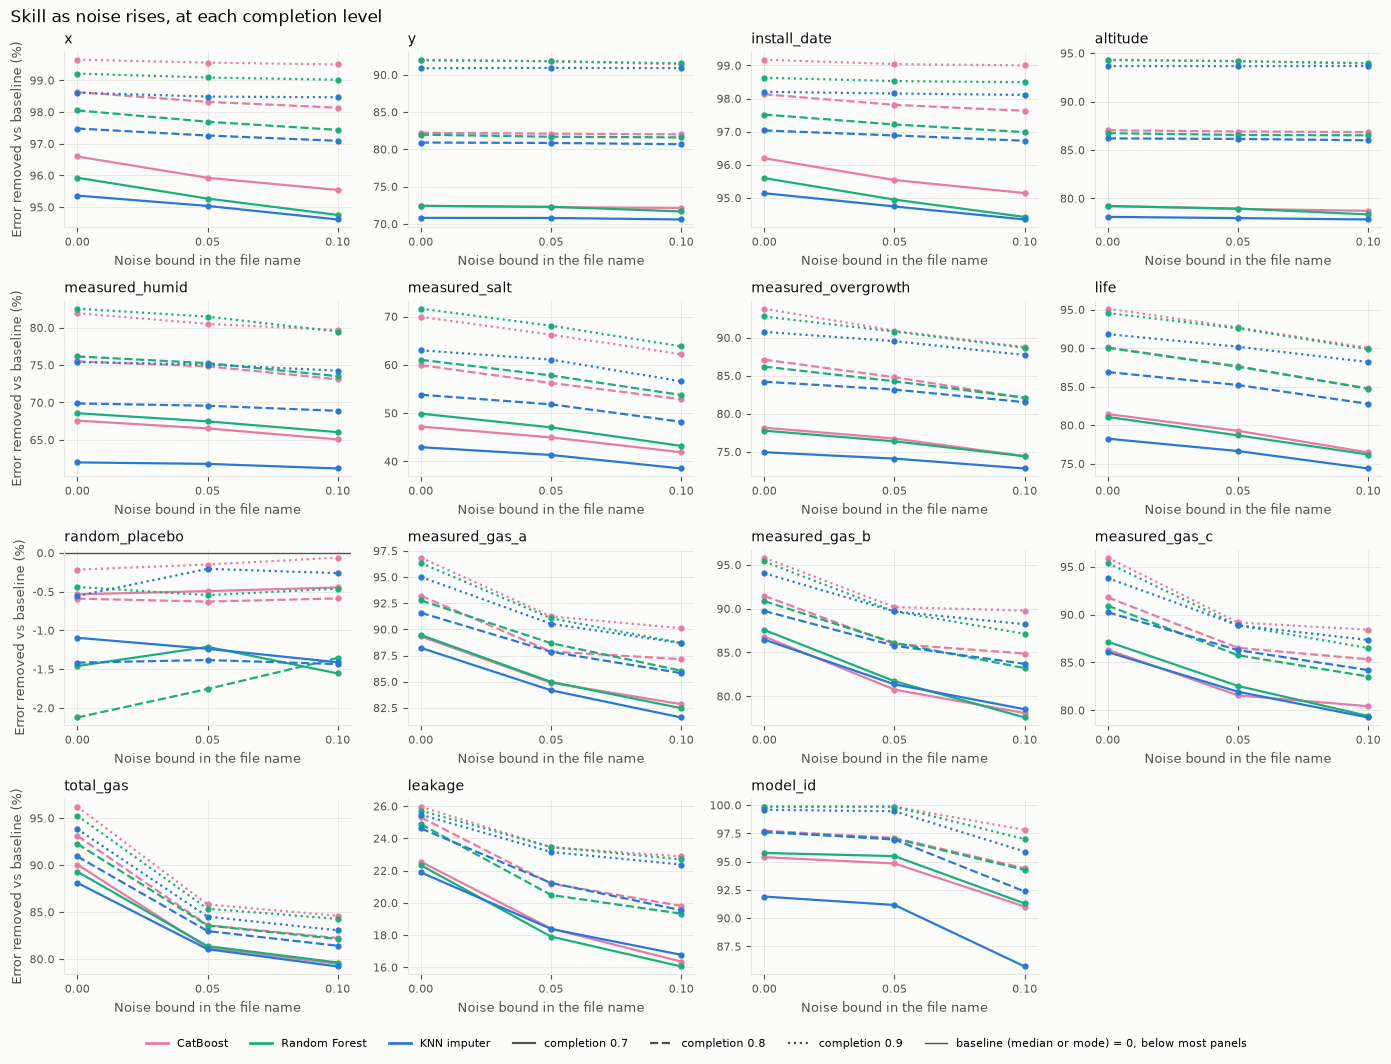

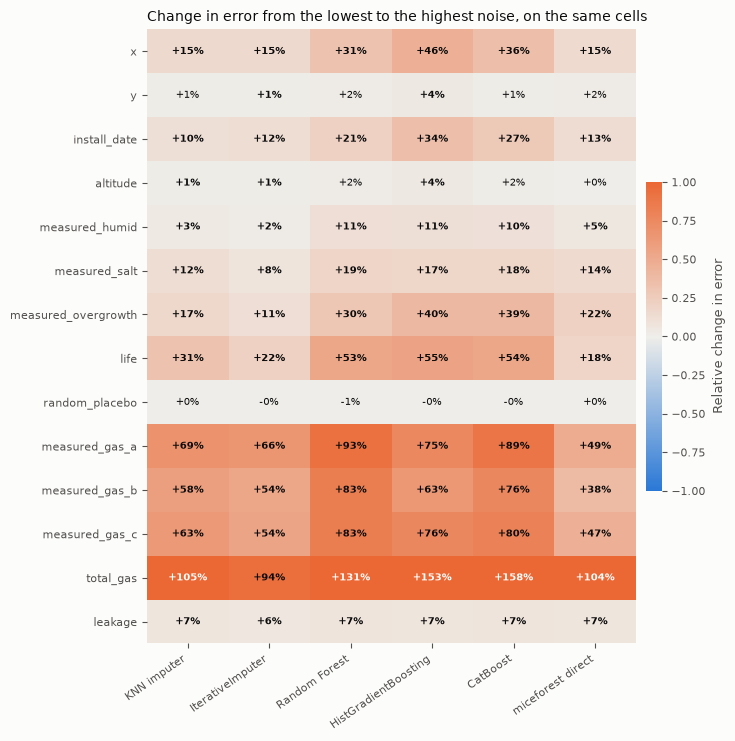

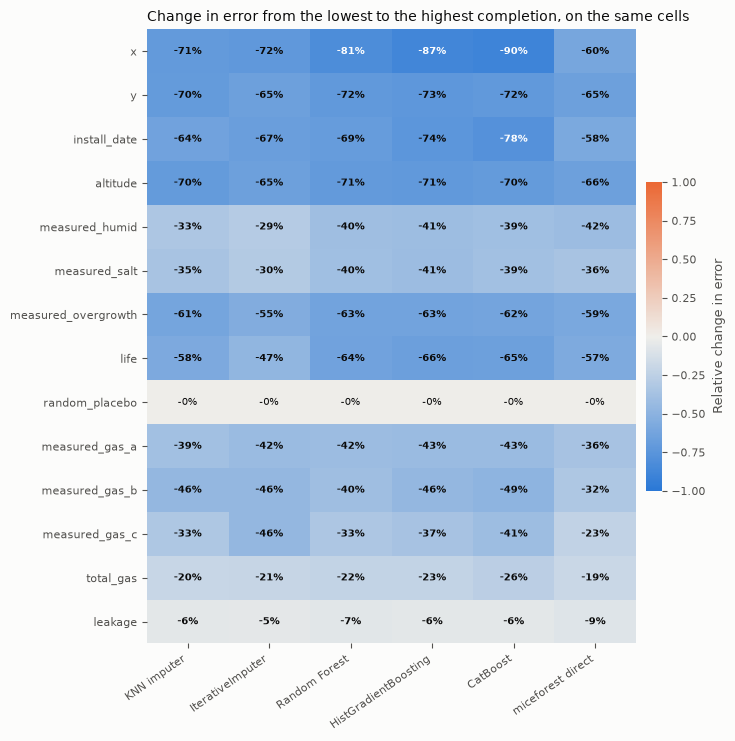

In [21]:
shown = STUDY.by_scenario[STUDY.by_scenario.method.isin(MAIN)]
fg.plot_lines(shown, "noise", "Skill as noise rises, at each completion level", FIGURES, "skill_by_noise",
              "Noise bound in the file name", MAIN, style="completion", style_label="completion")
completion_level, noise_level = STUDY.scenarios[REPRESENTATIVE].completion, STUDY.scenarios[REPRESENTATIVE].noise
for control, held, level, label in (("noise", "held completion", completion_level, "noise"),
                                    ("completeness", "held noise", noise_level, "completion")):
    matrix, marks = ev.effect_matrix(STUDY.effects, control, held, level)
    fg.plot_heatmap(matrix, f"Change in error from the lowest to the highest {label}, on the same cells", FIGURES,
                    f"{control}_effect", "Relative change in error", center=0.0, limit=1.0, marks=marks, fmt="{:+.0%}")

### 6.2 Linked columns visible in the row

A column's directly linked columns are those it is computed from and those computed from it, in the generator's definition. For each hidden cell, the number of them visible in the same row is counted from measured data only. Each panel shows skill against the share that was visible, with one line style for each noise level. Groups with fewer than 30 cells are left out.

The table gives the same numbers for the lead model in the representative scenario.

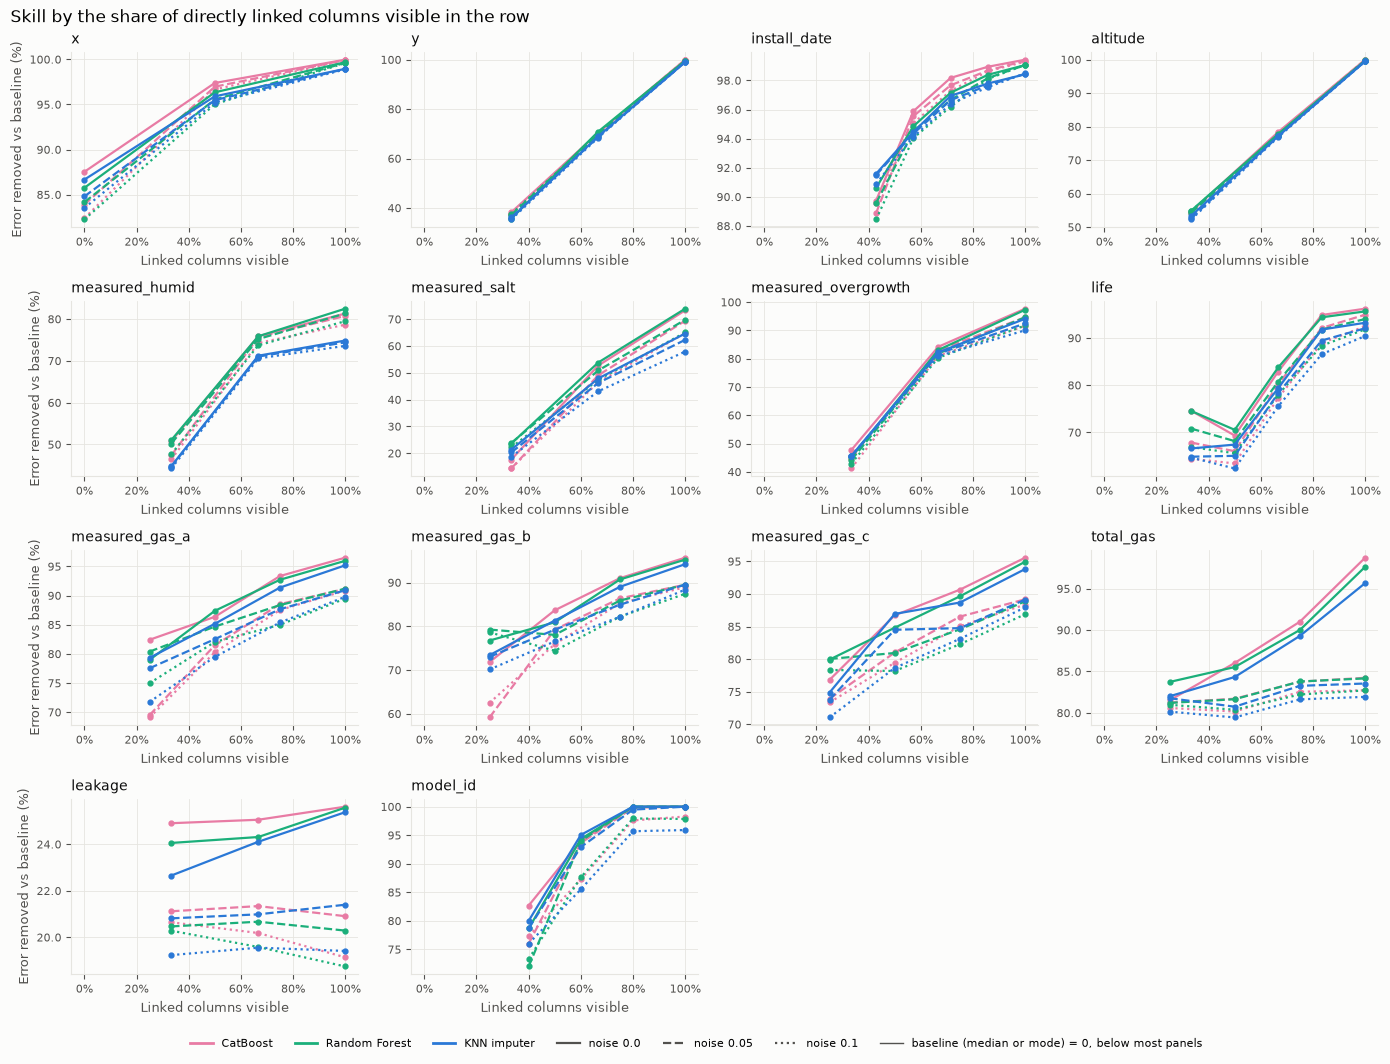

,visible,n,skill
target,,,
x,0 of 2,83,0.839
x,1 of 2,610,0.970
x,2 of 2,1297,0.999
y,1 of 3,189,0.377
y,2 of 3,743,0.703
y,3 of 3,1031,1.000
install_date,3 of 7,58,0.889
install_date,4 of 7,220,0.955
install_date,5 of 7,520,0.977


In [22]:
seen = ev.add_scenario_levels(STUDY.visibility, STUDY.scenarios)
fg.plot_lines(seen[seen.method.isin(MAIN)], "share seen", "Skill by the share of directly linked columns visible in the row",
              FIGURES, "skill_by_visible_links", "Linked columns visible", MAIN, style="noise", style_label="noise", share_seen=True)
lead_seen = seen[seen.method.eq(LEAD) & seen.scenario.eq(REPRESENTATIVE)].copy()
lead_seen["visible"] = lead_seen.seen.astype(int).astype(str) + " of " + lead_seen.links.astype(int).astype(str)
lead_seen["order"] = lead_seen.target.map(list(TARGETS).index)
display(lead_seen.sort_values(["order", "seen"]).set_index("target")[["visible", "n", "skill"]].round(3))

### 6.3 Position of the true value

Cells are grouped by where their true value lies in the column: the lowest tenth, the next fifth, the middle 40%, and the same on the high side. This grouping is known only afterwards, so it explains errors and sets no rule for filling data.

The chart shows the mean signed error in units of the column's spread, from the lowest band on the left to the highest on the right. A line that falls from left to right means that low values are estimated too high and high values too low. The baseline is the dashed line. The table gives the size of the error for the lead model.

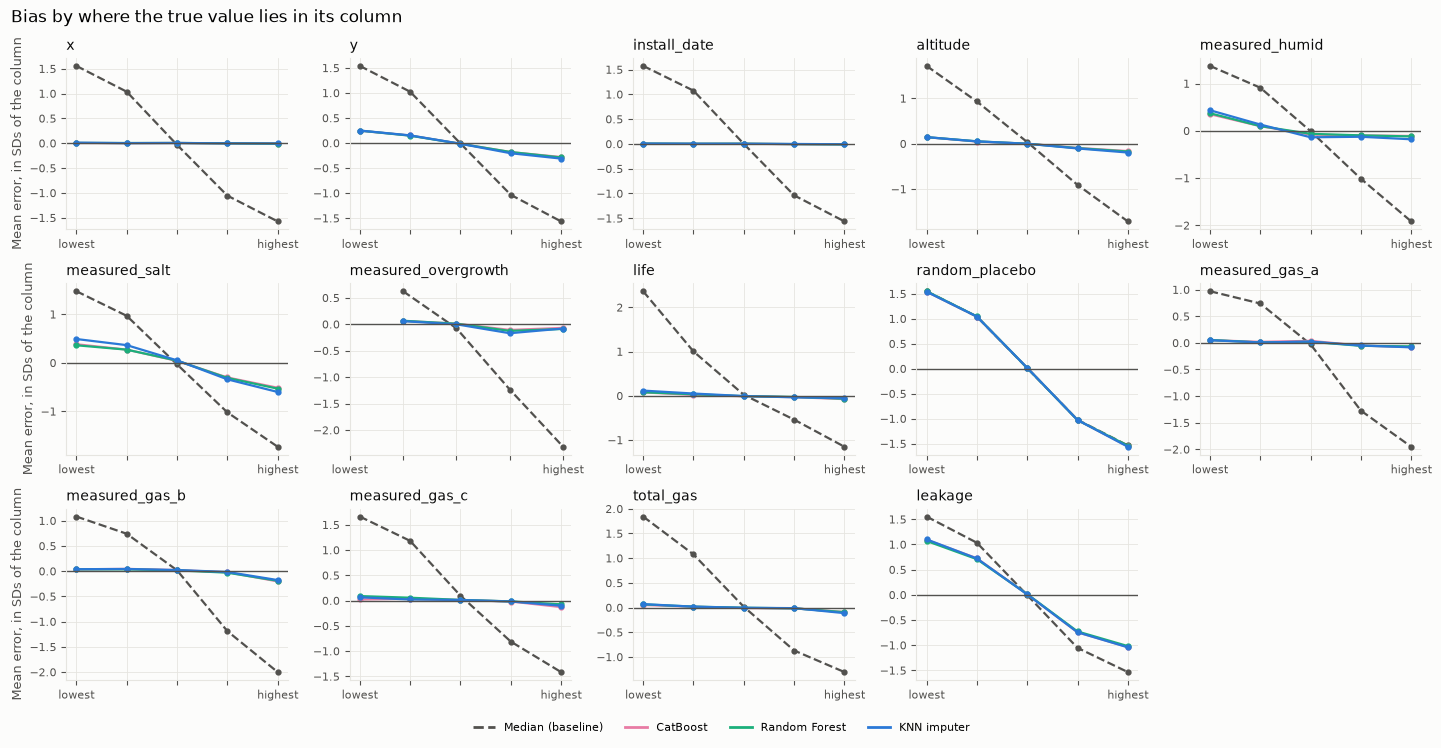

band,lowest 10%,10% to 30%,middle 40%,70% to 90%,highest 10%
target,,,,,
x,0.005,0.011,0.020,0.014,0.012
y,0.249,0.152,0.085,0.187,0.280
install_date,0.010,0.014,0.024,0.019,0.017
altitude,0.147,0.072,0.096,0.120,0.164
measured_humid,0.372,0.222,0.185,0.162,0.220
measured_salt,0.450,0.352,0.293,0.412,0.591
measured_overgrowth,NaN,0.063,0.139,0.191,0.154
life,0.146,0.119,0.071,0.075,0.111
random_placebo,1.542,1.043,0.356,1.027,1.556


In [23]:
fg.plot_bands(STUDY.bands, ["Median"] + MAIN, list(fl.BANDS), FIGURES)
display(STUDY.bands[STUDY.bands.method.eq(LEAD)].pivot(index="target", columns="band", values="error in SD")
        .reindex(index=list(NUMERIC_TARGETS), columns=list(fl.BANDS)).round(3))

### 6.4 How cells were chosen for hiding

The three scenarios below hide the same share of cells: at random, more for older assets, and more for higher values. The chart shows the skill of the lead model in each.

Skill alone can hide a shift. When higher values are hidden more often, the visible values of a column are lower than the hidden ones, so an estimate that leans on the visible range can be too low. The first table therefore shows the mean signed error, in units of the column's spread, for the lead model and the baseline. The second table shows mean skill by age third, to check that assets with more gaps are also filled less well.

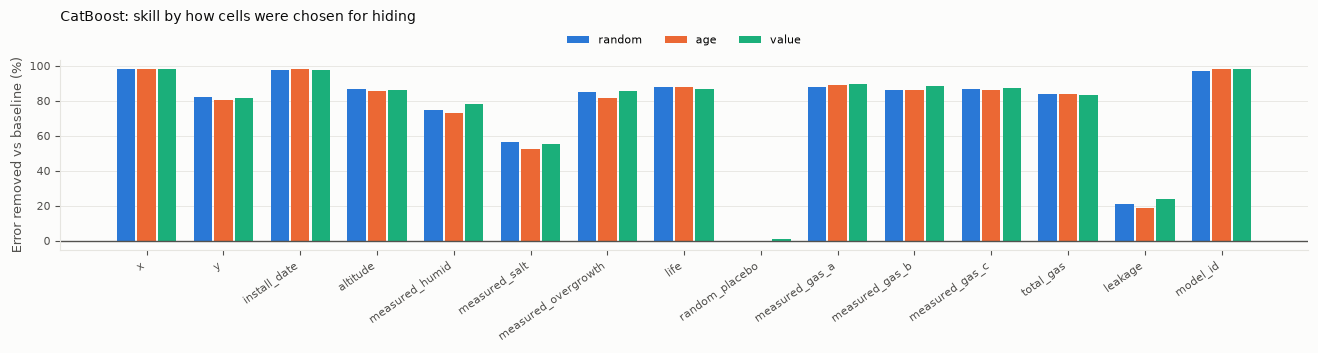

method              Median               CatBoost              
mechanism           random    age  value   random    age  value
target                                                         
x                    0.006  0.401 -0.435    0.001  0.001 -0.000
y                    0.001  0.037 -0.374   -0.014 -0.012 -0.058
install_date         0.008  0.383 -0.388    0.001  0.001 -0.000
altitude             0.044  0.284 -0.326   -0.008 -0.008 -0.040
measured_humid      -0.081  0.012 -0.499   -0.009 -0.007 -0.042
measured_salt       -0.046 -0.009 -0.417   -0.003  0.011 -0.045
measured_overgrowth -0.307 -0.216 -0.667   -0.003 -0.014 -0.027
life                 0.223  0.126 -0.155   -0.007  0.006  0.003
random_placebo       0.044  0.037 -0.385    0.042  0.038 -0.340
measured_gas_a      -0.226 -0.649 -0.733    0.006  0.003 -0.014
measured_gas_b      -0.149 -0.363 -0.617   -0.002  0.001 -0.001
measured_gas_c       0.162  0.179 -0.301   -0.003 -0.000 -0.005
total_gas            0.096 -0.306 -0.294   -0.009 -0.008 -0.014
leakage             -0.023  0.005 -0.415   -0.007 -0.005 -0.237

age third                middle third  newest third  oldest third
method        mechanism                                          
CatBoost      age               0.777         0.859         0.762
              random            0.773         0.839         0.784
              value             0.789         0.838         0.786
KNN imputer   age               0.752         0.850         0.738
              random            0.758         0.831         0.761
              value             0.768         0.828         0.763
Random Forest age               0.778         0.861         0.756
              random            0.775         0.839         0.777
              value             0.790         0.838         0.784

In [24]:
scores = STUDY.mechanism_scores
lead_scores = scores[scores.method.eq(LEAD)].pivot(index="target", columns="mechanism", values="skill").reindex(list(TARGETS))
order = [m for m in ("random", "age", "value") if m in lead_scores]
fg.plot_bars(lead_scores[order], f"{LEAD}: skill by how cells were chosen for hiding", FIGURES, "skill_by_mechanism",
             "Error removed vs baseline (%)")
bias = scores[scores.method.isin([LEAD, "Median"]) & scores.target.ne("model_id")]
display(bias.pivot(index="target", columns=["method", "mechanism"], values="bias in SD").reindex(list(NUMERIC_TARGETS)).round(3))
groups = fl.mechanism_groups(CELLS, STUDY.truth, STUDY.scenarios, STUDY.config)
display(groups[groups.method.isin(MAIN)].pivot(index=["method", "mechanism"], columns="age third", values="skill").round(3))

### 6.5 Kind of relationship

Columns are grouped by how the generator builds them. The table shows the mean skill of the lead model for each kind: in the reference scenario, in its best and worst generator scenario, and when few linked columns are visible.

In [25]:
with pd.option_context("display.max_colwidth", 70):
    display(STUDY.kinds.round(3))

,kind of relationship,columns,reference,best scenario,worst scenario,few linked columns visible
0,near copy of another column,"x, install_date",0.981,0.994,0.953,0.839
1,exact sum,"altitude, y, total_gas",0.842,0.942,0.768,0.566
2,threshold,measured_overgrowth,0.848,0.938,0.744,0.435
3,random draw scaled by another column,"measured_humid, measured_salt",0.655,0.759,0.535,0.296
4,decline that depends on the model,"measured_gas_a, measured_gas_b, measured_gas_c",0.868,0.962,0.805,0.686
5,product that depends on the model,life,0.876,0.951,0.765,0.603
6,category drawn from a moving window,model_id,0.971,0.999,0.910,NaN
7,"independent draw, seen only through its effects",leakage,0.212,0.260,0.164,0.220
8,no relationship,random_placebo,-0.006,-0.001,-0.006,NaN


## 7. Form of the failure

Chapter 6 showed where skill falls. This chapter describes what the estimates look like when it does.

### 7.1 Estimates collapse towards a constant

The slope of predictions against the truth is 1 when estimates follow the truth fully and 0 when they are a constant. The chart shows this slope against the share of linked columns visible. A slope that falls with the share means that a model answers a cell it cannot see into with a value near the centre of the column.

The table gives the spread of imputed values relative to the spread of the truth, over all hidden cells of the representative scenario. A value below 1 means that completed columns are narrower than the real ones.

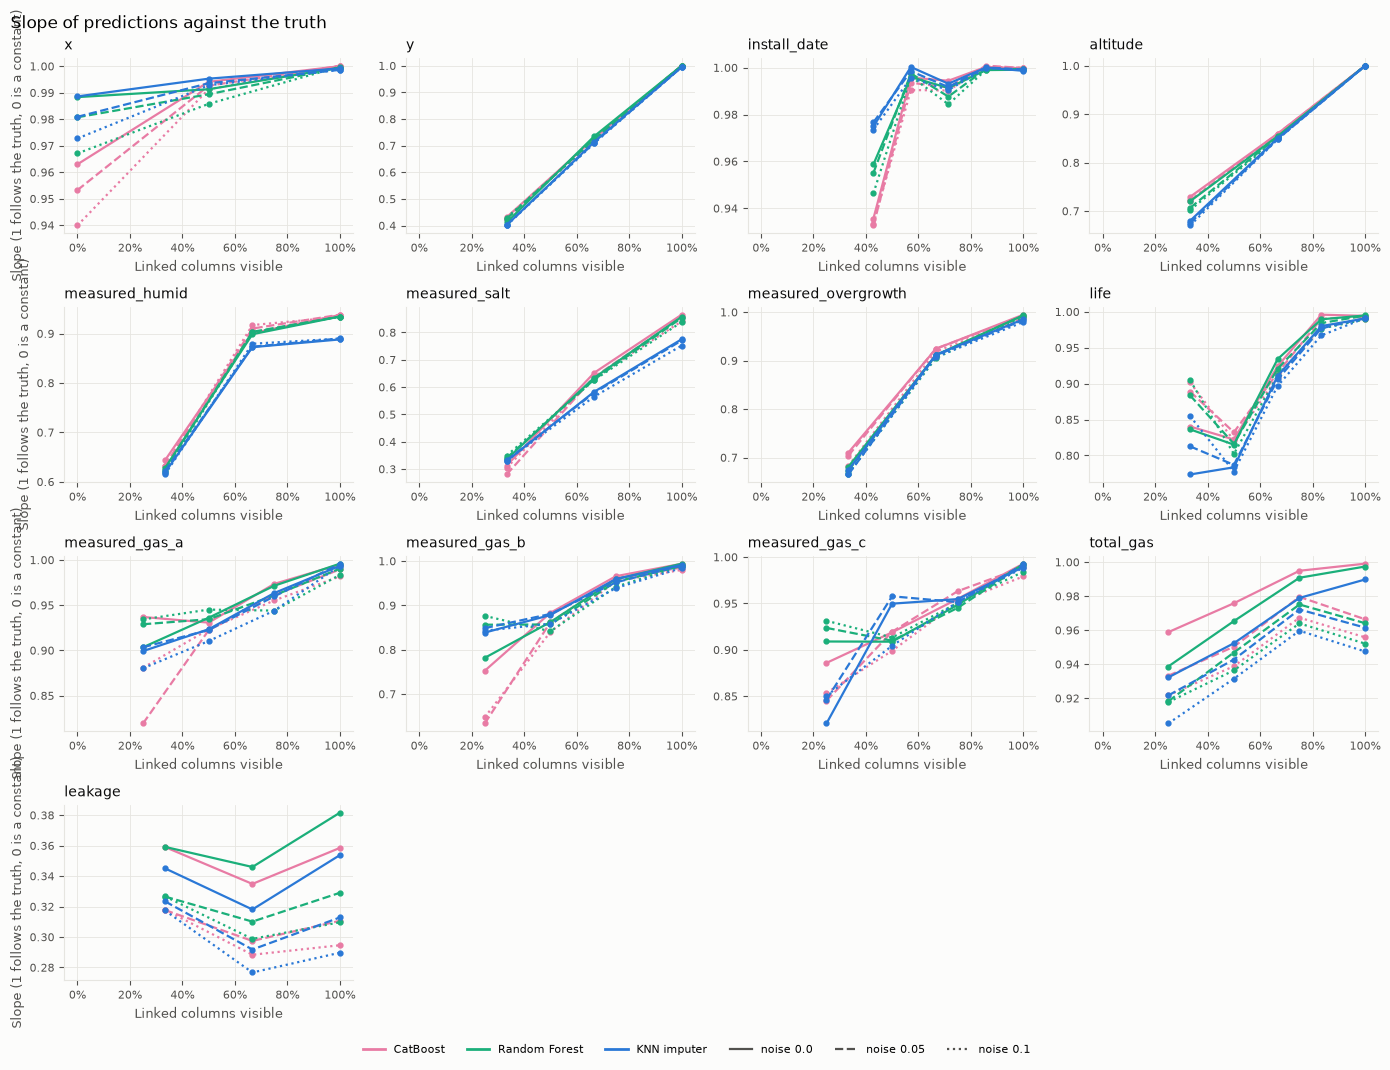

method,Median,CatBoost,Random Forest,KNN imputer,IterativeImputer,miceforest direct
target,,,,,,
x,0.014,0.998,0.997,0.998,0.991,0.995
y,0.017,0.912,0.913,0.905,0.916,0.899
install_date,0.010,0.998,0.997,0.999,0.990,0.993
altitude,0.012,0.954,0.951,0.947,0.911,0.949
measured_humid,0.003,0.950,0.945,0.926,0.956,0.923
measured_salt,0.009,0.872,0.861,0.808,0.819,0.822
measured_overgrowth,0.010,0.973,0.966,0.962,0.940,0.952
life,0.005,0.983,0.982,0.976,0.962,0.957
random_placebo,0.004,0.096,0.192,0.144,0.078,0.196


In [26]:
slopes = ev.add_scenario_levels(STUDY.shrinkage, STUDY.scenarios)
fg.plot_lines(slopes[slopes.method.isin(MAIN)], "share seen", "Slope of predictions against the truth", FIGURES, "slope_by_visible_links",
              "Linked columns visible", MAIN, style="noise", style_label="noise", share_seen=True, y="slope",
              ylabel="Slope (1 follows the truth, 0 is a constant)", targets=list(NUMERIC_TARGETS))
spread = fl.overall_shrinkage(CELLS, STUDY.config)
display(spread[spread.scenario.eq(REPRESENTATIVE)].pivot(index="target", columns="method", values="spread ratio")
        .reindex(list(NUMERIC_TARGETS))[["Median"] + SHOWN].round(3))

### 7.2 Values outside the valid range

The table shows the share of raw predictions outside the range a column allows, before they are limited to it. Scoring uses the limited values. A column with a floor or a ceiling, such as `measured_overgrowth`, is where an averaging model can leave the range.

In [27]:
ranges = fl.range_table(CELLS, STUDY.config)
display(ranges[ranges.scenario.eq(REPRESENTATIVE)].pivot(index="target", columns="method", values="outside valid range")
        .reindex(list(NUMERIC_TARGETS))[SHOWN].round(4))

method,CatBoost,Random Forest,KNN imputer,IterativeImputer,miceforest direct
target,,,,,
x,0.0090,0.0070,0.0090,0.0000,0.0015
y,0.0086,0.0096,0.0051,0.0000,0.0000
install_date,0.0005,0.0005,0.0010,0.0000,0.0000
altitude,0.0000,0.0000,0.0000,0.0000,0.0000
measured_humid,0.0025,0.0015,0.0020,0.0000,0.0005
measured_salt,0.0208,0.0183,0.0142,0.0056,0.0005
measured_overgrowth,0.1685,0.1552,0.2001,0.0000,0.1031
life,0.0000,0.0000,0.0000,0.0000,0.0000
random_placebo,0.0000,0.0000,0.0000,0.0000,0.0000


### 7.3 Gradual or sudden

The table describes the shape of the two declines for the lead model.

- **Noise**: the skill lost from the lowest to the highest noise, and the share of that loss that comes at the first step. A share near 1 means that the first amount of noise does most of the damage.
- **Hidden linked columns**: skill with every linked column visible and with the fewest, and the share of the loss that comes when the first one is hidden. A low share means that one hidden column is tolerated and several are not.

Shares are left empty where the loss is under 0.02.

In [28]:
display(fl.decline_table(STUDY.by_scenario, STUDY.visibility, STUDY.config).round(3))

,target,skill lost to noise,share lost at the first noise step,skill with every linked column,skill with the fewest,share lost when the first linked column is hidden
0,x,0.005,NaN,0.999,0.839,0.185
1,y,0.002,NaN,1.000,0.377,0.477
2,install_date,0.005,NaN,0.994,0.889,0.064
3,altitude,0.002,NaN,1.000,0.543,0.479
4,measured_humid,0.024,0.277,0.807,0.474,0.152
5,measured_salt,0.071,0.524,0.694,0.143,0.369
6,measured_overgrowth,0.050,0.458,0.947,0.446,0.234
7,life,0.053,0.459,0.949,0.678,0.104
8,random_placebo,-0.000,NaN,NaN,NaN,NaN
9,measured_gas_a,0.061,0.880,0.911,0.695,0.121


### 7.4 Relationships between columns

A completed table can have accurate cells and still distort how columns relate. The first table compares correlations in completed data with correlations in the truth, across all 91 pairs of numeric columns, on the rows that hold an imputed cell of the pair. A gap of 0 means that the correlation is unchanged.

The second table checks three definitions directly on completed rows. The reference is the residual in rows with nothing imputed, which is the level that measurement noise alone produces.

In [29]:
gaps = STUDY.correlations[STUDY.correlations.method.isin(["Median"] + SHOWN)]
display(gaps.pivot(index="method", columns="scenario", values="mean gap").reindex(["Median"] + SHOWN).round(4))
consistency = STUDY.consistency[STUDY.consistency.method.isin(["Median"] + MAIN)]
wide = consistency.pivot(index=["relation", "scenario"], columns="method", values="mean residual in completed rows")[["Median"] + MAIN]
wide["fully observed rows"] = consistency.groupby(["relation", "scenario"])["mean residual in fully observed rows"].first()
display(wide.round(4))

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.05-age,completion0.8-noise0.05-value,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,,,
Median,0.2148,0.2144,0.2143,0.2148,0.2141,0.2124,0.2196,0.2140,0.2130,0.2124,0.2122
CatBoost,0.0134,0.0133,0.0149,0.0089,0.0098,0.0100,0.0163,0.0118,0.0058,0.0071,0.0100
Random Forest,0.0123,0.0118,0.0136,0.0099,0.0097,0.0094,0.0165,0.0121,0.0058,0.0069,0.0098
KNN imputer,0.0134,0.0127,0.0151,0.0109,0.0109,0.0108,0.0185,0.0133,0.0077,0.0089,0.0111
IterativeImputer,0.0132,0.0122,0.0138,0.0119,0.0118,0.0118,0.0206,0.0140,0.0084,0.0092,0.0113
miceforest direct,0.0130,0.0126,0.0142,0.0108,0.0107,0.0108,0.0163,0.0120,0.0066,0.0078,0.0107


method                                                          Median  CatBoost  Random Forest  KNN imputer  fully observed rows
relation                            scenario                                                                                     
altitude = x + y + 100              completion0.8-noise0.0     27.4631    0.0470         0.1554       0.2514               0.0000
                                    completion0.8-noise0.05    27.4631    0.0615         0.1785       0.2530               0.0000
                                    completion0.8-noise0.1     27.4631    0.0700         0.1887       0.2571               0.0000
overgrowth = max(2 humid - salt, 0) completion0.8-noise0.0      0.2366    0.0119         0.0098       0.0224               0.0000
                                    completion0.8-noise0.05     0.2362    0.0141         0.0123       0.0233               0.0174
                                    completion0.8-noise0.1      0.2365    0.0185         0.0172       0.0260               0.0348
total_gas = gas a + b + c           completion0.8-noise0.0   1146.5662   14.8638        22.6688      40.6763               0.0000
                                    completion0.8-noise0.05  1184.4284  244.2872       256.8057     245.8139             389.9461
                                    completion0.8-noise0.1   1305.4964  585.5014       599.4747     591.9143             779.8922

### 7.5 Whether a model signals its own errors

For `model_id`, a model gives a probability with its answer. The tables compare that confidence with accuracy, first by the number of linked columns visible and then by scenario. `sure and wrong` is the share of cells answered wrongly with a probability of 0.9 or more. Confidence that falls together with accuracy means that the errors can be found without knowing the truth.

The numeric estimates of these models are single values and carry no such signal.

In [30]:
by_seen = fl.confidence_table(CELLS, STUDY.config)
display(by_seen[by_seen.method.isin(MAIN)].sort_values(["method", "seen"]).round(3))
by_scenario = fl.confidence_table(CELLS, STUDY.config, by="scenario")
display(by_scenario[by_scenario.method.eq(LEAD)].sort_values("scenario").round(3))

,method,seen,n,accuracy,confidence,sure and wrong,confidence minus accuracy
21,CatBoost,2,98,0.816,0.865,0.00,0.049
20,CatBoost,3,388,0.954,0.952,0.00,-0.001
18,CatBoost,4,815,0.999,0.992,0.00,-0.006
19,CatBoost,5,650,1.000,0.999,0.00,-0.001
3,KNN imputer,2,98,0.837,0.697,0.01,-0.139
2,KNN imputer,3,388,0.948,0.805,0.00,-0.143
0,KNN imputer,4,815,0.996,0.880,0.00,-0.116
1,KNN imputer,5,650,1.000,0.930,0.00,-0.070
10,Random Forest,2,98,0.786,0.777,0.00,-0.009
8,Random Forest,3,388,0.956,0.889,0.00,-0.067


,method,scenario,n,accuracy,confidence,sure and wrong,confidence minus accuracy
29,CatBoost,completion0.7-noise0.0,2968,0.967,0.963,0.000,-0.004
27,CatBoost,completion0.7-noise0.05,2968,0.963,0.959,0.001,-0.003
28,CatBoost,completion0.7-noise0.1,2968,0.935,0.931,0.002,-0.004
31,CatBoost,completion0.8-noise0.0,1965,0.984,0.982,0.000,-0.002
30,CatBoost,completion0.8-noise0.05,1965,0.979,0.979,0.000,-0.001
32,CatBoost,completion0.8-noise0.1,1965,0.960,0.954,0.003,-0.006
34,CatBoost,completion0.9-noise0.0,995,0.999,0.997,0.000,-0.002
33,CatBoost,completion0.9-noise0.05,995,0.999,0.995,0.000,-0.004
35,CatBoost,completion0.9-noise0.1,995,0.984,0.978,0.000,-0.006


### 7.6 Differences between models

Four of the models share the ridge base, so part of any agreement between them can come from their structure. The chart shows the skill of each main model with no ridge base (open marker) and with it (filled marker), in the representative scenario. The table adds the two references.

The last table shows how far two models fail on the same cells: it is the rank correlation between their cell errors, averaged over columns. A value near 1 means that the models are wrong in the same places.

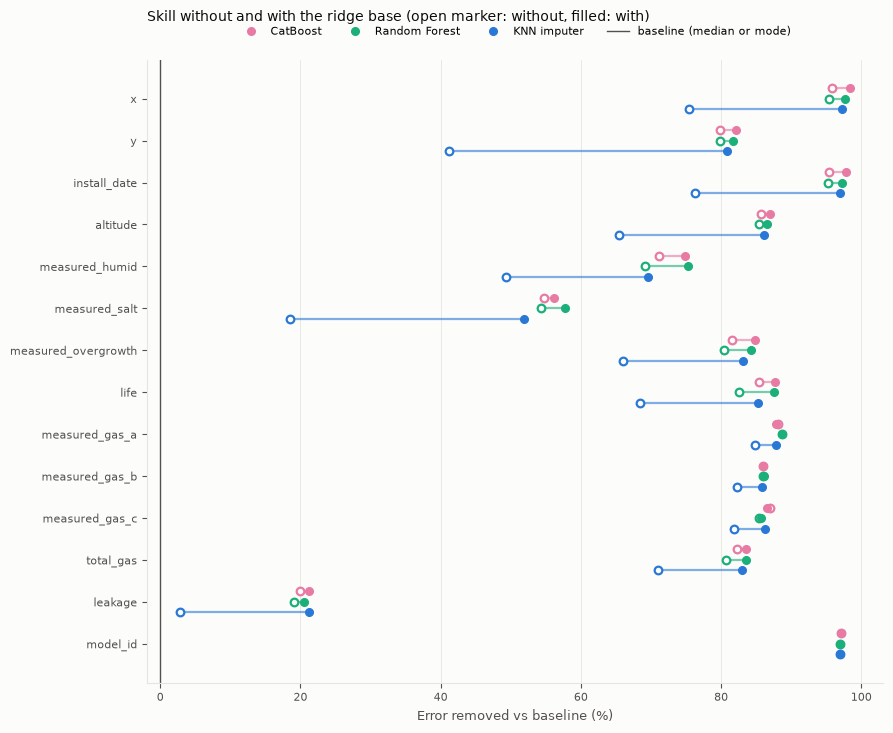

,CatBoost: no ridge,CatBoost: with ridge,Random Forest: no ridge,Random Forest: with ridge,KNN imputer: no ridge,KNN imputer: with ridge,HistGradientBoosting: no ridge,HistGradientBoosting: with ridge,IterativeImputer (ridge only),miceforest direct (boosted chain without the ridge)
x,0.958,0.983,0.954,0.977,0.754,0.973,0.958,0.984,0.970,0.953
y,0.799,0.821,0.799,0.817,0.411,0.809,0.798,0.819,0.781,0.785
install_date,0.954,0.978,0.953,0.972,0.762,0.969,0.955,0.979,0.967,0.949
altitude,0.857,0.869,0.854,0.866,0.654,0.861,0.854,0.867,0.843,0.849
measured_humid,0.712,0.748,0.692,0.753,0.494,0.696,0.714,0.751,0.663,0.722
measured_salt,0.547,0.562,0.543,0.578,0.185,0.518,0.551,0.581,0.466,0.549
measured_overgrowth,0.816,0.848,0.804,0.843,0.660,0.832,0.815,0.848,0.806,0.813
life,0.853,0.876,0.826,0.876,0.684,0.852,0.847,0.878,0.804,0.847
random_placebo,0.001,-0.006,-0.014,-0.018,-0.011,-0.014,-0.002,-0.009,-0.006,-0.010
measured_gas_a,0.882,0.879,0.887,0.887,0.848,0.879,0.879,0.879,0.867,0.885


method,CatBoost,Random Forest,KNN imputer,IterativeImputer,miceforest direct,HistGradientBoosting
method,,,,,,
CatBoost,1.00,0.79,0.75,0.69,0.58,0.86
Random Forest,0.79,1.00,0.75,0.67,0.61,0.81
KNN imputer,0.75,0.75,1.00,0.83,0.55,0.73
IterativeImputer,0.69,0.67,0.83,1.00,0.52,0.67
miceforest direct,0.58,0.61,0.55,0.52,1.00,0.59
HistGradientBoosting,0.86,0.81,0.73,0.67,0.59,1.00


In [31]:
structure = STUDY.structure.drop(index="random_placebo")
pairs = [(m, f"{m}: no ridge", f"{m}: with ridge", fg.METHOD_COLORS[m]) for m in MAIN if f"{m}: no ridge" in structure]
fg.plot_pairs(structure, pairs, "Skill without and with the ridge base", FIGURES, "ridge_base_effect", "Error removed vs baseline (%)")
display(STUDY.structure.round(3))
display(fl.error_overlap(CELLS, STUDY.config).round(2))

## 8. Causes

Each section states one possible cause and tests it with a comparison.

### 8.1 Limits of the data and limits of the model

Some error cannot be removed by any model, because the data does not hold the answer. Two references separate that part.

The chart splits each column's baseline error into three parts for the lead model: the share removed, the share lost because linked columns were hidden, and the share that remains even when every linked column is visible.

The tables then apply the generator's own definition to the visible inputs (`Formula`), on hidden cells whose defining inputs are all visible. Values are MAE. With no noise the formula is exact, so a model's error there is its own. With noise the formula inherits the noise of its inputs, and a model can do better because other columns help to average that noise out. The last table shows how much of each column the other true columns could explain at all.

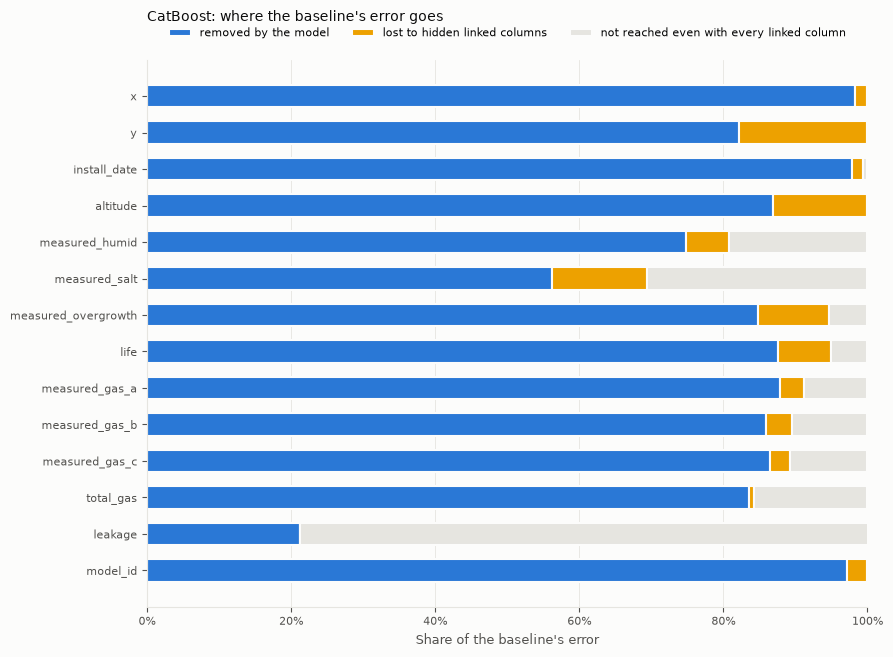

,skill over all hidden cells,skill with every linked column visible,cells with every linked column visible,lost to hidden linked columns,not reached even with every linked column
target,,,,,
x,0.983,0.999,1297.0,0.016,0.001
y,0.821,1.000,1031.0,0.178,0.000
install_date,0.978,0.994,430.0,0.015,0.006
altitude,0.869,1.000,1042.0,0.130,0.000
measured_humid,0.748,0.807,1007.0,0.059,0.193
measured_salt,0.562,0.694,1002.0,0.132,0.306
measured_overgrowth,0.848,0.947,1021.0,0.099,0.053
life,0.876,0.949,537.0,0.073,0.051
measured_gas_a,0.879,0.911,854.0,0.033,0.089


**completion0.8-noise0.0**

,method,Median,CatBoost,Random Forest,KNN imputer,IterativeImputer,miceforest direct,Formula
relation,n,,,,,,,
altitude from x and y,1308,34.024,0.008,0.094,0.184,0.217,0.896,0.000
x from altitude and y,1299,24.711,0.084,0.256,0.366,0.410,1.027,0.000
y from altitude and x,1278,25.280,0.009,0.104,0.244,0.345,1.250,0.000
total_gas from gas readings,1030,1109.235,13.659,25.998,48.593,48.364,54.231,0.000
gas a from total and other readings,1018,1248.808,17.297,24.955,42.027,38.839,69.645,0.000
overgrowth from humidity and salt,1244,0.307,0.007,0.008,0.019,0.028,0.015,0.000
life from all its inputs,537,294.559,11.168,12.854,19.948,35.008,25.566,0.000
"leakage from gases, date and model",608,0.097,0.074,0.073,0.074,0.074,0.076,0.065


**completion0.8-noise0.05**

,method,Median,CatBoost,Random Forest,KNN imputer,IterativeImputer,miceforest direct,Formula
relation,n,,,,,,,
altitude from x and y,1308,34.024,0.011,0.106,0.164,0.203,0.922,0.000
x from altitude and y,1299,24.711,0.117,0.312,0.399,0.418,1.108,0.000
y from altitude and x,1278,25.280,0.019,0.107,0.234,0.350,1.276,0.000
total_gas from gas readings,1030,1109.235,178.060,177.136,180.946,183.976,191.284,387.321
gas a from total and other readings,1018,1251.182,112.996,112.081,120.922,132.953,112.058,322.255
overgrowth from humidity and salt,1244,0.307,0.017,0.017,0.024,0.031,0.020,0.015
life from all its inputs,537,294.559,14.915,17.610,23.387,36.866,26.468,8.484
"leakage from gases, date and model",608,0.097,0.078,0.079,0.078,0.078,0.080,NaN


**completion0.8-noise0.1**

,method,Median,CatBoost,Random Forest,KNN imputer,IterativeImputer,miceforest direct,Formula
relation,n,,,,,,,
altitude from x and y,1308,34.024,0.020,0.104,0.169,0.206,0.946,0.000
x from altitude and y,1299,24.711,0.135,0.342,0.422,0.419,1.145,0.000
y from altitude and x,1278,25.280,0.020,0.112,0.232,0.353,1.308,0.000
total_gas from gas readings,1030,1109.235,194.308,196.423,200.424,204.696,210.546,774.642
gas a from total and other readings,1018,1251.807,124.805,140.581,144.555,161.761,155.406,644.510
overgrowth from humidity and salt,1244,0.307,0.027,0.027,0.032,0.039,0.030,0.030
life from all its inputs,537,294.559,22.086,24.049,28.226,40.920,30.102,16.969
"leakage from gases, date and model",608,0.097,0.080,0.080,0.080,0.080,0.081,NaN


,target,R2 from all other true columns,"best R2, representative scenario","best R2, easiest scenario"
0,x,1.000,0.996,0.999
1,y,0.999,0.832,0.923
2,install_date,1.000,0.996,0.999
3,altitude,1.000,0.920,0.965
4,measured_humid,0.954,0.878,0.932
5,measured_salt,0.894,0.691,0.808
6,measured_overgrowth,0.999,0.926,0.977
7,life,0.995,0.953,0.990
8,random_placebo,-0.104,-0.012,-0.001
9,measured_gas_a,0.999,0.961,0.994


In [32]:
information = STUDY.information.rename(columns={"skill over all hidden cells": "removed by the model"})
fg.plot_stacked(information, ["removed by the model", "lost to hidden linked columns", "not reached even with every linked column"],
                [fg.SERIES[0], fg.SERIES[3], fg.GRID], f"{LEAD}: where the baseline's error goes", FIGURES, "error_split",
                "Share of the baseline's error")
display(STUDY.information.round(3))
for scenario in (NOISE_FREE, REPRESENTATIVE, HIGH_NOISE):
    display(Markdown(f"**{scenario}**"))
    display(rel.relation_matrix(STUDY.relations, scenario)[["Median"] + SHOWN + [rel.FORMULA]].round(3))
display(rel.recoverable_table(STUDY.truth[REPRESENTATIVE], NUMERIC, STUDY.config).round(3))

### 8.2 Missing information

If hidden linked columns are the cause of section 6.2, the models should rely on those columns when they are visible. This is tested with single-target forest and CatBoost models, because a chain covers every column at once and a column's influence on one target cannot be read from it. Each predictor is shuffled in held-out rows, and the added error is measured against observed labels, so truth is not involved. A value of 1 means that the shuffle cost as much as replacing the model with a constant guess.

The first table places every column a model relies on (importance above 0.02) in the generator's definition:

- **direct**: the target is computed from it, or it is computed from the target.
- **defines a column together with the target**: for example `x` and `y`, which define `altitude` together.
- **linked through another column**: for example `altitude` and `install_date`, which are both computed from `x` and `y`.
- **stands in for a near copy**: `x` and `install_date` are near copies, so one can replace the other.
- **no link**: the definition gives no connection.

The second table lists the strongest columns relied on outside the target's own definition. The heatmap shows all values for the lead model, with direct links in bold.

method                                                          Random Forest                                                              CatBoost                                               
scenario                                               completion0.8-noise0.0 completion0.8-noise0.05 completion0.8-noise0.1 completion0.8-noise0.0 completion0.8-noise0.05 completion0.8-noise0.1
direct links                                                           54.000                  54.000                 54.000                 54.000                  54.000                 54.000
direct links relied on                                                  0.741                   0.648                  0.630                  0.833                   0.778                  0.741
columns relied on                                                      73.000                  65.000                 63.000                 83.000                  78.000                 77.000
of those: direct                                                        0.548                   0.538                  0.540                  0.542                   0.538                  0.519
of those: defines a column together with the target                     0.164                   0.200                  0.206                  0.157                   0.179                  0.195
of those: linked through another column                                 0.274                   0.246                  0.238                  0.289                   0.269                  0.273
of those: stands in for a near copy of a linked column                  0.014                   0.015                  0.016                  0.012                   0.013                  0.013
of those: no link                                                       0.000                   0.000                  0.000                  0.000                   0.000                  0.000

,target,predictor,importance,link
0,leakage,total_gas,0.531194,linked through another column
1,altitude,install_date,0.317361,linked through another column
2,leakage,x,0.313052,stands in for a near copy of a linked column
3,total_gas,x,0.271802,linked through another column
4,x,total_gas,0.206071,linked through another column
5,life,x,0.159773,linked through another column
6,x,model_id,0.094059,linked through another column
7,measured_gas_a,x,0.090550,linked through another column
8,life,measured_gas_c,0.081125,linked through another column
9,life,measured_gas_b,0.080562,linked through another column


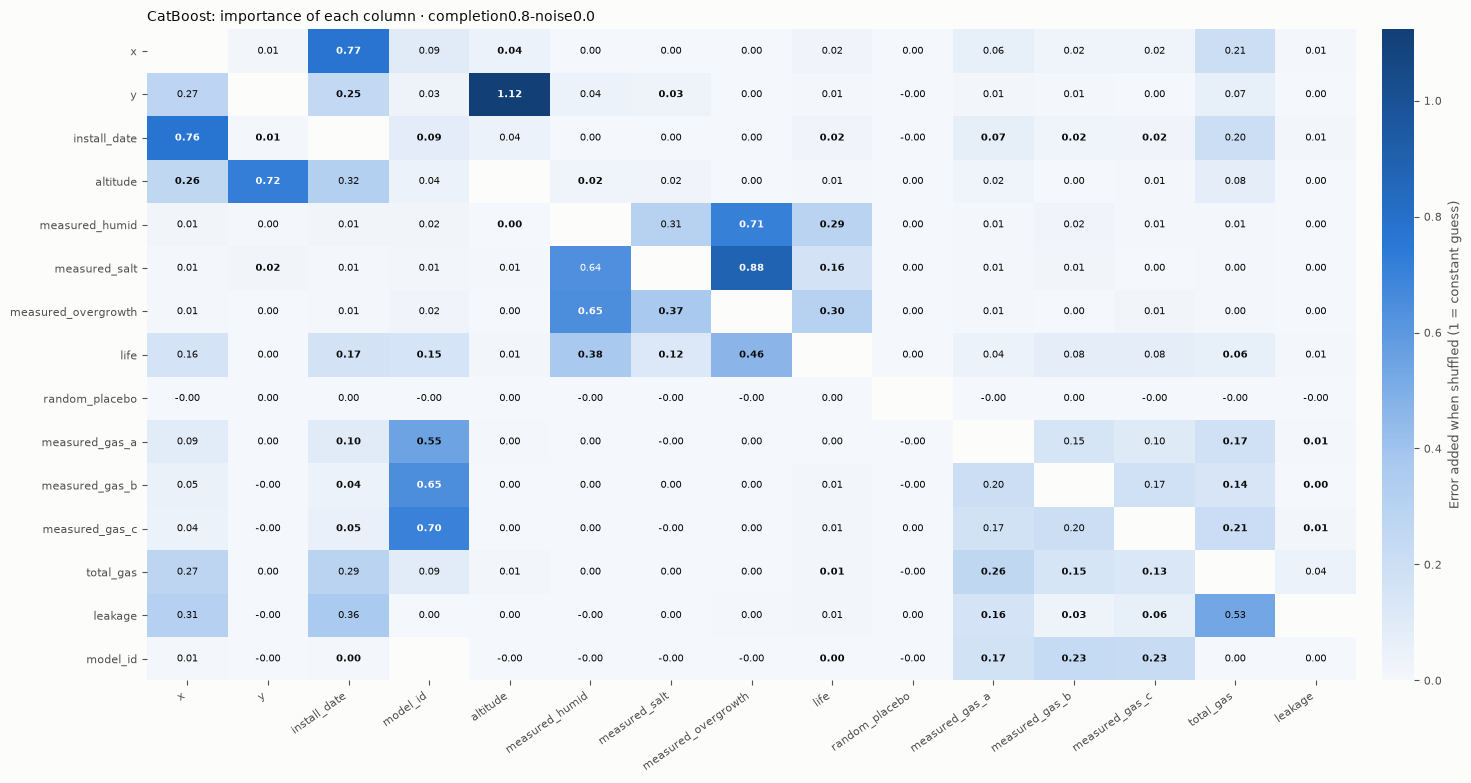

In [33]:
with pd.option_context("display.max_colwidth", 60):
    display(STUDY.links.set_index(["method", "scenario"]).round(3).T)
    display(fl.unexplained_links(STUDY.all_importance, NOISE_FREE, LEAD))
mean_importance = STUDY.all_importance.groupby(["method", "scenario", "target", "predictor"], sort=False).importance.mean().reset_index()
fg.plot_importance(ev.importance_matrix(mean_importance, NOISE_FREE, LEAD), f"{LEAD}: importance of each column · {NOISE_FREE}",
                   FIGURES, "importance")

### 8.3 Noise carried from linked columns

Noise can reach an estimate in two ways: through the visible values of the column itself, which the model learns from, and through the linked columns it reads. The table gives both, as the mean measurement error at the highest noise level in units of the column's spread, beside the change in the model's error on the same cells.

Columns such as `total_gas`, `life` and `model_id` are exact themselves. If their error still rises with noise, the noise was carried in from their linked columns. The chart plots the error change against the largest noise that reaches a column by either way.

,target,noise in the column itself,mean noise in its linked columns,largest noise in a linked column,error change from noise,skill at the lowest noise,skill at the highest noise,largest noise reaching the column
0,x,0.000,0.000,0.000,0.357,0.986,0.981,0.000
1,y,0.000,0.028,0.084,0.012,0.822,0.820,0.084
2,install_date,0.000,0.192,0.430,0.267,0.981,0.976,0.430
3,altitude,0.000,0.027,0.080,0.015,0.870,0.868,0.080
4,measured_humid,0.080,0.015,0.046,0.098,0.755,0.731,0.080
5,measured_salt,0.084,0.015,0.046,0.177,0.599,0.529,0.084
6,measured_overgrowth,0.046,0.055,0.084,0.392,0.871,0.821,0.084
7,life,0.000,0.042,0.084,0.536,0.901,0.848,0.084
8,measured_gas_a,0.331,0.000,0.000,0.891,0.932,0.872,0.331
9,measured_gas_b,0.392,0.000,0.000,0.761,0.915,0.849,0.392


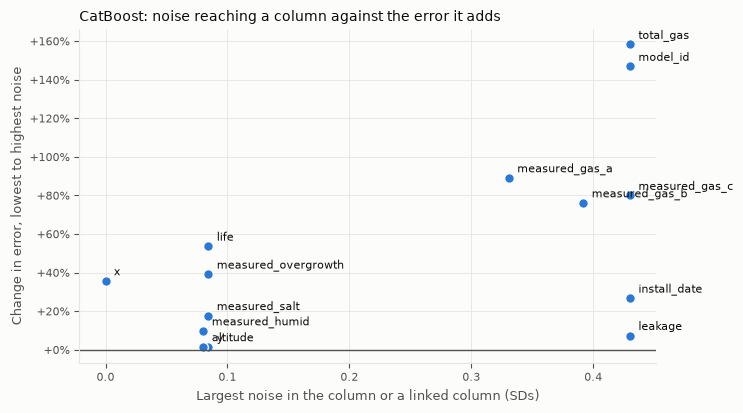

In [34]:
noise = STUDY.noise.copy()
noise["largest noise reaching the column"] = noise[["noise in the column itself", "largest noise in a linked column"]].max(axis=1)
display(noise.round(3))
fg.plot_scatter(noise, "largest noise reaching the column", "error change from noise", "target",
                f"{LEAD}: noise reaching a column against the error it adds", FIGURES, "noise_carried",
                "Largest noise in the column or a linked column (SDs)", "Change in error, lowest to highest noise")

### 8.4 Removed columns and substitutes

Each block of columns is removed according to what it measures, and the chained models are refitted. Values show the relative change in error, so a positive value means that the block carried information for that target. Empty cells are targets inside the removed block.

Two results matter for the causes. A large change shows which block a target depends on. A small change after removing a directly linked block shows that another column took its place, which a near copy can do.

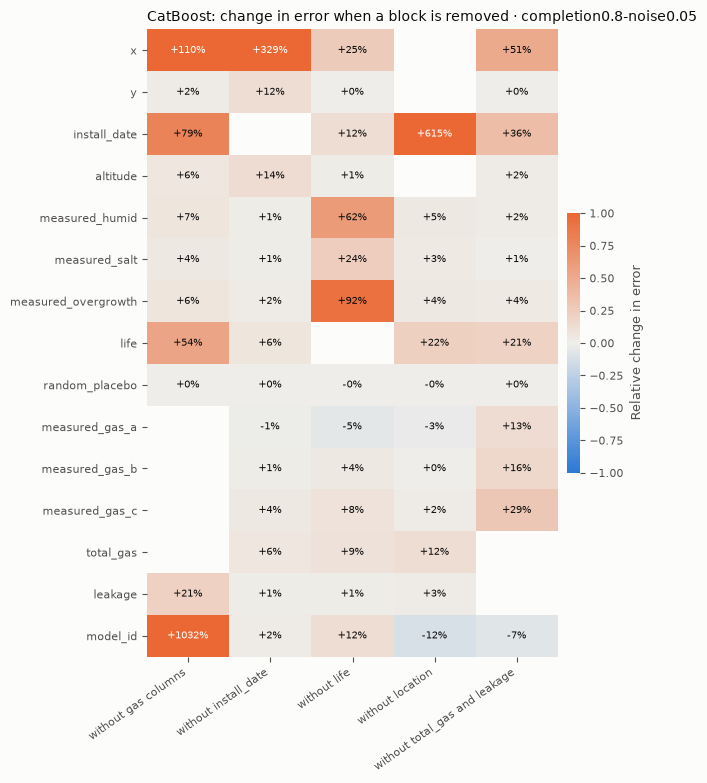

method                                             CatBoost  IterativeImputer  KNN imputer  Random Forest
target              variant                                                                              
altitude            without gas columns               0.861             0.834        0.857          0.859
                    without install_date              0.851             0.823        0.841          0.845
                    without life                      0.868             0.842        0.859          0.866
                    without total_gas and leakage     0.866             0.839        0.863          0.866
install_date        without gas columns               0.961             0.947        0.955          0.953
                    without life                      0.975             0.964        0.964          0.970
                    without location                  0.843             0.809        0.826          0.843
                    without total_gas and leakage     0.970             0.957        0.967          0.965
leakage             without gas columns               0.044             0.017        0.021          0.035
                    without install_date              0.206             0.201        0.205          0.198
                    without life                      0.206             0.203        0.206          0.201
                    without location                  0.190             0.185        0.189          0.179
life                without gas columns               0.809             0.724        0.788          0.805
                    without install_date              0.869             0.795        0.841          0.868
                    without location                  0.849             0.781        0.825          0.854
                    without total_gas and leakage     0.851             0.789        0.837          0.854
measured_gas_a      without install_date              0.880             0.866        0.876          0.885
                    without life                      0.885             0.862        0.877          0.883
                    without location                  0.882             0.863        0.876          0.882
                    without total_gas and leakage     0.863             0.842        0.862          0.864
measured_gas_b      without install_date              0.858             0.844        0.855          0.858
                    without life                      0.854             0.836        0.847          0.857
                    without location                  0.859             0.842        0.857          0.857
                    without total_gas and leakage     0.837             0.820        0.838          0.843
measured_gas_c      without install_date              0.859             0.838        0.859          0.853
                    without life                      0.854             0.826        0.850          0.853
                    without location                  0.862             0.836        0.857          0.849
                    without total_gas and leakage     0.826             0.793        0.819          0.817
measured_humid      without gas columns               0.732             0.646        0.679          0.732
                    without install_date              0.746             0.660        0.692          0.750
                    without life                      0.593             0.521        0.556          0.598
                    without location                  0.737             0.653        0.690          0.742
                    without total_gas and leakage     0.743             0.658        0.698          0.744
measured_overgrowth without gas columns               0.838             0.789        0.814          0.831
                    without install_date              0.845             0.803        0.828          0.839
                    without life                      0.707             0.667 

In [35]:
removed = STUDY.ablation[STUDY.ablation.scenario.eq(REPRESENTATIVE)]
matrix = removed[removed.method.eq(LEAD)].pivot(index="target", columns="variant", values="relative change").reindex(list(TARGETS))
fg.plot_heatmap(matrix, f"{LEAD}: change in error when a block is removed · {REPRESENTATIVE}", FIGURES, "ablation",
                "Relative change in error", center=0.0, limit=1.0, fmt="{:+.0%}")
worst = removed[removed.method.isin(MAIN + ["IterativeImputer"])].pivot_table(index=["target", "variant"], columns="method", values="skill without")
display(worst.round(3))

### 8.5 Structure of the model

The table gives mean skill by kind of relationship for each structure: the main models with and without the ridge base, the ridge alone and the boosted chain with no ridge. Where the ridge raises a local model, the relationship is one the local model approximates poorly on its own. Where all structures agree, the limit lies in the data.

In [36]:
by_kind = STUDY.structure.assign(kind=[fl.KIND_OF[t] for t in STUDY.structure.index]).groupby("kind", sort=False).mean()
with pd.option_context("display.max_colwidth", 60):
    display(by_kind.round(3))

,CatBoost: no ridge,CatBoost: with ridge,Random Forest: no ridge,Random Forest: with ridge,KNN imputer: no ridge,KNN imputer: with ridge,HistGradientBoosting: no ridge,HistGradientBoosting: with ridge,IterativeImputer (ridge only),miceforest direct (boosted chain without the ridge)
kind,,,,,,,,,,
near copy of another column,0.956,0.981,0.953,0.975,0.758,0.971,0.957,0.982,0.968,0.951
exact sum,0.826,0.842,0.820,0.839,0.592,0.833,0.823,0.841,0.817,0.818
random draw scaled by another column,0.630,0.655,0.617,0.665,0.339,0.607,0.633,0.666,0.564,0.636
threshold,0.816,0.848,0.804,0.843,0.660,0.832,0.815,0.848,0.806,0.813
product that depends on the model,0.853,0.876,0.826,0.876,0.684,0.852,0.847,0.878,0.804,0.847
no relationship,0.001,-0.006,-0.014,-0.018,-0.011,-0.014,-0.002,-0.009,-0.006,-0.010
decline that depends on the model,0.871,0.868,0.867,0.868,0.830,0.866,0.863,0.864,0.851,0.867
"independent draw, seen only through its effects",0.199,0.212,0.191,0.205,0.029,0.212,0.194,0.212,0.208,0.193
category drawn from a moving window,0.971,0.971,0.970,0.970,0.970,0.970,0.973,0.973,NaN,0.977


### 8.6 Explanations that are ruled out

Three checks test whether results could be produced by the evaluation itself.

- **Leakage.** The first table counts predictions made for a visible cell or from a model that saw the row, and hidden cells not predicted exactly once. Every count should be 0.
- **Invented structure.** `random_placebo` is unrelated to every other column. A model that beat the baseline on it would be finding structure that does not exist. The table shows its skill in every scenario, and the next one the importance given to it as a predictor.
- **The fold split.** The representative scenario is repeated with two more fold seeds. The last table shows mean skill for each seed.

In [37]:
display(fl.integrity_table(CELLS, STUDY.measured, STUDY.config))
placebo = STUDY.by_scenario[STUDY.by_scenario.target.eq("random_placebo")]
display(placebo.pivot(index="method", columns="scenario", values="skill").round(4))
used = STUDY.all_importance[STUDY.all_importance.predictor.eq("random_placebo") & STUDY.all_importance.target.ne("random_placebo")]
display(used.groupby(["method", "scenario"]).importance.agg(["mean", "max"]).round(4))
seeds = fl.skill_by(CELLS[CELLS.scenario.eq(REPRESENTATIVE) & CELLS.experiment.isin(["main", "stability"])
                          & CELLS.target.ne("random_placebo")], ["method", "seed", "target"])
display(seeds.groupby(["method", "seed"]).skill.mean().unstack().drop(index=["Median", "Mode"], errors="ignore").round(4))

,check,count,expected
0,Predictions for cells that were visible,0,0
1,Predicted rows outside the held-out fold,0,0
2,Cells predicted more than once by a method,0,0
3,Method and target groups that do not cover every hidden cell,0,0


scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
CatBoost,-0.0053,-0.0049,-0.0045,-0.0059,-0.0063,-0.0059,-0.0022,-0.0015,-0.0006
HistGradientBoosting,-0.0071,-0.0068,-0.0066,-0.0099,-0.0086,-0.0057,0.0004,-0.0014,-0.0028
IterativeImputer,-0.0038,-0.0033,-0.0022,-0.0056,-0.0056,-0.0052,-0.0026,-0.0010,-0.0003
KNN imputer,-0.0109,-0.0124,-0.0141,-0.0142,-0.0138,-0.0143,-0.0056,-0.0021,-0.0026
Random Forest,-0.0146,-0.0121,-0.0155,-0.0212,-0.0175,-0.0135,-0.0044,-0.0054,-0.0046
miceforest direct,-0.0192,-0.0132,-0.0145,-0.0141,-0.0105,-0.0182,-0.0071,-0.0035,-0.0118


mean     max
method        scenario                               
CatBoost      completion0.8-noise0.0   0.0002  0.0051
              completion0.8-noise0.05  0.0001  0.0037
              completion0.8-noise0.1   0.0001  0.0050
Random Forest completion0.8-noise0.0   0.0001  0.0045
              completion0.8-noise0.05 -0.0000  0.0044
              completion0.8-noise0.1   0.0000  0.0041

seed,219,220,221
method,,,
CatBoost,0.8078,0.8085,0.8075
HistGradientBoosting,0.8087,0.8102,0.8094
IterativeImputer,0.7605,0.7586,0.7604
KNN imputer,0.7943,0.7939,0.7924
Random Forest,0.8069,0.8067,0.8047
miceforest direct,0.7899,0.7892,0.7907


## 9. What imputation gives a later analysis

An analysis that accepts only complete rows loses most of the table. The first table counts the rows with no missing cell in every scenario.

The second part compares eight summary values that an asset analysis might take from the table, such as mean `life` by model and the share of assets with low `life`. Each is computed from the truth and from several versions of the representative scenario:

- **rows with no missing cell**: what an analysis without imputation would use.
- **Median and Mode**: the baseline fill.
- **each model**: the completed table, with out-of-fold values.
- **measured values with true values in the gaps**: a perfect imputation, whose error comes from measurement noise alone.

Values are relative errors against the truth. The last table repeats the mean absolute error for the two scenarios of section 2.5.

In [38]:
display(fl.complete_rows_table(STUDY.measured, STUDY.scenarios).round(3))
downstream = STUDY.downstream
order = ["rows with no missing cell", "Median and Mode"] + [m for m in SHOWN if m in set(downstream.source)] + ["measured values with true values in the gaps"]
with pd.option_context("display.max_colwidth", 60):
    display(downstream.pivot(index="quantity", columns="source", values="relative error")[order].round(4))
display(STUDY.downstream_by_scenario.reindex(order).round(4))

,scenario,mechanism,rows,rows with no missing cell,share of rows,share of cells visible
0,completion0.7-noise0.0,random,10000,48,0.005,0.700
1,completion0.7-noise0.05,random,10000,48,0.005,0.700
2,completion0.7-noise0.1,random,10000,48,0.005,0.700
3,completion0.8-noise0.0,random,10000,348,0.035,0.800
4,completion0.8-noise0.05,random,10000,348,0.035,0.800
5,completion0.8-noise0.1,random,10000,348,0.035,0.800
6,completion0.9-noise0.0,random,10000,2064,0.206,0.901
7,completion0.9-noise0.05,random,10000,2064,0.206,0.901
8,completion0.9-noise0.1,random,10000,2064,0.206,0.901
9,completion0.8-noise0.05-age,age,10000,603,0.060,0.801


source,rows with no missing cell,Median and Mode,CatBoost,Random Forest,KNN imputer,miceforest direct,measured values with true values in the gaps
quantity,,,,,,,
90th percentile of overgrowth,0.0396,-0.0728,-0.0002,-0.0007,-0.0033,-0.0036,0.0032
life lost per day installed,-0.1556,-0.1479,0.0077,0.0042,0.0001,0.0039,0.0000
"mean life, model 0",-0.0001,-0.0002,0.0000,0.0000,0.0000,0.0000,0.0000
"mean life, model 1",-0.0009,0.0001,0.0000,0.0000,0.0000,-0.0000,0.0000
"mean life, model 2",-0.0001,0.0005,-0.0000,0.0000,0.0000,0.0000,0.0000
"mean life, model 3",0.0004,0.0000,-0.0000,-0.0000,-0.0000,-0.0000,0.0000
share of assets with life below the lowest tenth,0.0632,-0.1910,-0.0020,-0.0050,-0.0120,-0.0060,0.0000
spread of total gas (SD),-0.0072,-0.1116,-0.0034,-0.0042,-0.0047,-0.0056,0.0000


,completion0.8-noise0.05,completion0.8-noise0.05-age,completion0.8-noise0.05-value
source,,,
rows with no missing cell,0.0334,0.2433,0.0443
Median and Mode,0.0655,0.0590,0.0417
CatBoost,0.0017,0.0020,0.0021
Random Forest,0.0018,0.0028,0.0033
KNN imputer,0.0025,0.0031,0.0026
miceforest direct,0.0024,0.0037,0.0035
measured values with true values in the gaps,0.0004,0.0003,0.0005


## 10. Limits of the experiment

- The data is synthetic, and there is one generated truth table, so the study does not measure variation between generated datasets.
- The two scenarios of section 2.5 are simple forms of missingness that depends on the asset. They do not cover every mechanism, and each was run at one completion and noise level.
- `x` and `install_date` are near copies of each other, because assets were installed in grid order. High skill on these columns says little about model quality.
- A noise level does not mean equal difficulty across columns. Section 8.3 gives the noise of each column in units of its spread.
- Four models share the ridge base, so agreement between them can partly be a result of their structure. Section 7.6 measures that share.
- Importance comes from single-target models, not from the chained models that are scored. The ablation in section 8.4 tests chained models directly.
- The models give single values for numeric columns. The study does not test methods that return a range of plausible values.
- IterativeImputer can stop at its pass limit before it converges. Section 4.3 reports how often, and the effect of other limits.
- All development used this one dataset. Settings never saw a hidden cell, but no independent dataset was held back.
- Shared settings were chosen on three scenarios and may not be the best elsewhere. The search covered a fixed list of candidates, so it does not establish any method's ceiling.
- The candidates were written by people who knew how the data was generated. Models receive no relationship and a fixed rule made the final choice, but second-order terms were offered because such relationships were expected.
- A chained model trains on estimates that used the row's own label, which is not available for a hidden cell. Removing this effect improved the selection score by 0.25%, so the simpler form was kept.
- Row intervals are conditional on fitted models. Neighbouring grid rows are related, so intervals may be narrower than they should be.
- `life`, `total_gas` and `leakage` are exact by design, so results for and from these columns are better than noisy measurements would allow.

## Appendix

### A.1 All models, with the size of their differences

The first table gives the best method for each target, where `lead` is `clear` when the gap to the next method is both separated and at least 5%. The chart compares every method with the baseline on the same cells, with 95% row-bootstrap intervals. The intervals resample rows for fitted models. They do not include refitting or the randomness of the dataset itself. The last table compares the best two methods for each target.

,target,best,skill,next,gap to next,lead,noise 0 to 0.1,completion 0.7 to 0.9
0,x,HistGradientBoosting,0.984,CatBoost,0.080,not separated,+46%,-87%
1,y,CatBoost,0.821,HistGradientBoosting,0.012,not separated,+1% (not clear),-72%
2,install_date,HistGradientBoosting,0.979,CatBoost,0.048,not separated,+34%,-74%
3,altitude,CatBoost,0.869,HistGradientBoosting,0.017,not separated,+2% (not clear),-70%
4,measured_humid,Random Forest,0.753,HistGradientBoosting,0.008,not separated,+11%,-40%
5,measured_salt,HistGradientBoosting,0.581,Random Forest,0.008,not separated,+17%,-41%
6,measured_overgrowth,HistGradientBoosting,0.848,CatBoost,0.001,not separated,+40%,-63%
7,life,HistGradientBoosting,0.878,CatBoost,0.014,not separated,+55%,-66%
8,measured_gas_a,Random Forest,0.887,miceforest direct,0.013,not separated,+93%,-42%
9,measured_gas_b,Random Forest,0.861,CatBoost,0.010,not separated,+83%,-40%


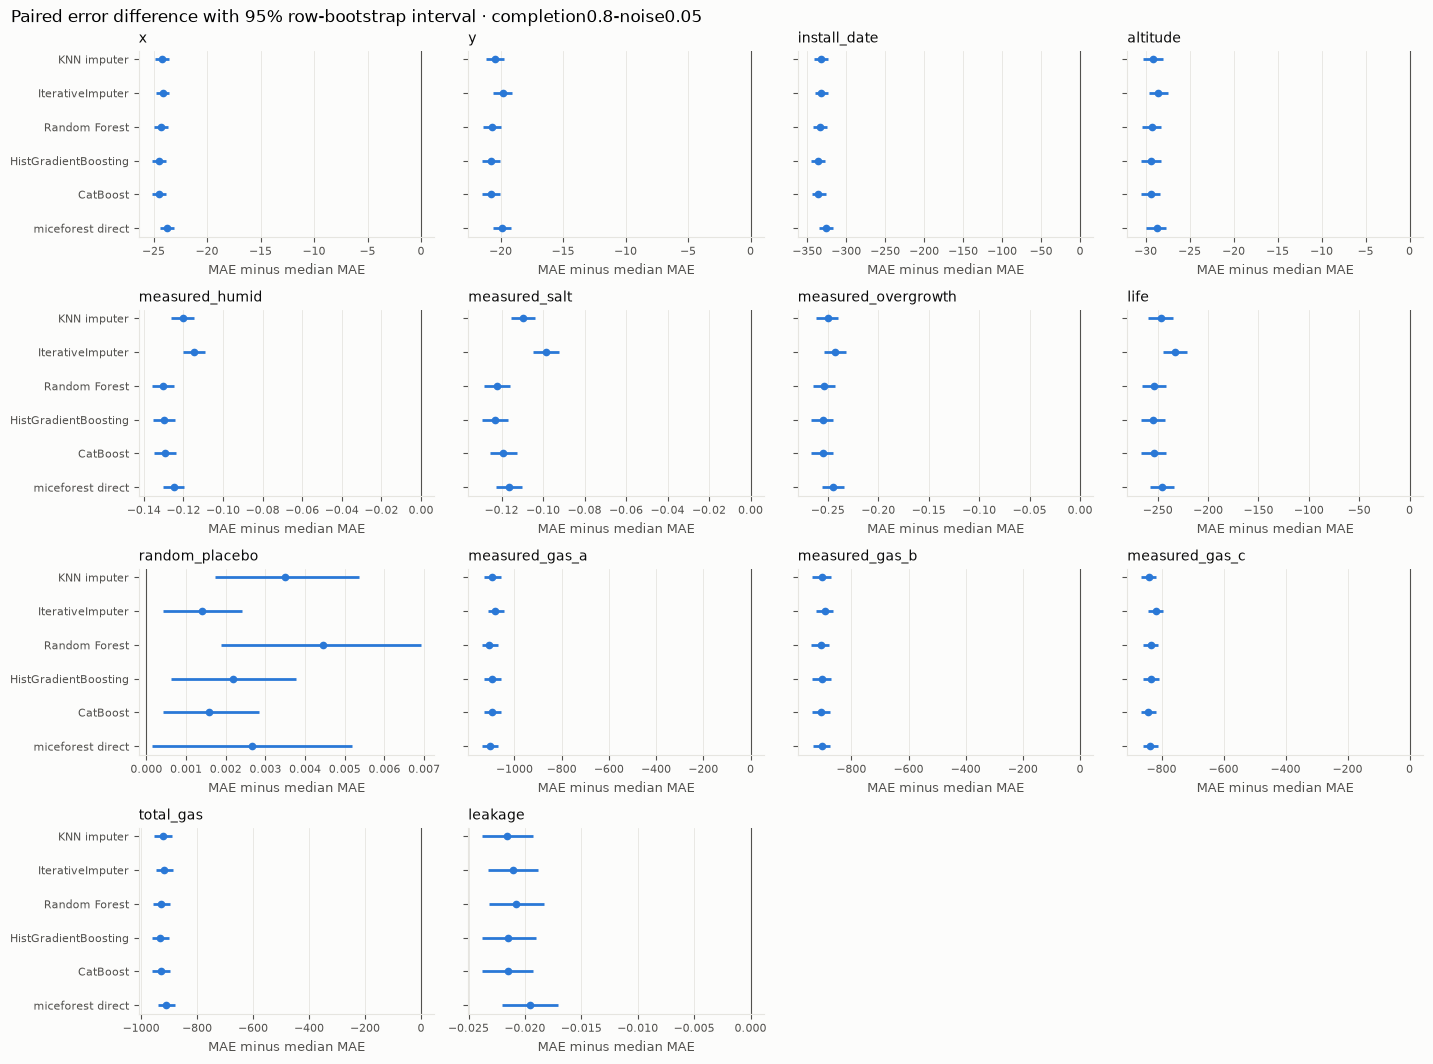

,target,first,second,metric,difference,low,high,relative gap
0,x,HistGradientBoosting,CatBoost,MAE,0.03116,-0.00503,0.06834,0.08042
1,y,CatBoost,HistGradientBoosting,MAE,0.05404,-0.07629,0.17932,0.01193
2,install_date,HistGradientBoosting,CatBoost,MAE,0.34668,-0.18210,0.87082,0.04831
3,altitude,CatBoost,HistGradientBoosting,MAE,0.07757,-0.04525,0.18849,0.01749
4,measured_humid,Random Forest,HistGradientBoosting,MAE,0.00036,-0.00093,0.00163,0.00834
5,measured_salt,HistGradientBoosting,Random Forest,MAE,0.00068,-0.00131,0.00285,0.00762
6,measured_overgrowth,HistGradientBoosting,CatBoost,MAE,0.00005,-0.00162,0.00162,0.00107
7,life,HistGradientBoosting,CatBoost,MAE,0.48601,-1.09268,1.99654,0.01375
8,random_placebo,IterativeImputer,CatBoost,MAE,0.00018,-0.00027,0.00064,0.00069
9,measured_gas_a,Random Forest,miceforest direct,MAE,1.86905,-6.47689,10.20114,0.01323


In [39]:
display(STUDY.targets.round(3))
fg.plot_paired(PAIRS, REPRESENTATIVE, FIGURES)
closest = PAIRS[PAIRS.scenario.eq(REPRESENTATIVE) & PAIRS.comparison.eq("best two")].copy()
closest["relative gap"] = closest["second error"] / closest["first error"].where(closest["first error"] > 0) - 1
closest = closest.set_index("target").reindex(list(TARGETS)).reset_index()
display(closest[["target", "first", "second", "metric", "difference", "low", "high", "relative gap"]].round(5))

### A.2 Different fold splits

The representative scenario is repeated with two more fold seeds. The same rows are reused across seeds, so this shows sensitivity to the split and does not add new samples.

In [40]:
seed_numeric, seed_labels = ev.stability_table(NUMERIC, CATEGORY, STUDY.config)
print("Worst rank of each method across seeds:")
display(seed_numeric.pivot(index="target", columns="method", values="worst rank").reindex(list(NUMERIC_TARGETS))[list(NUMERIC_METHODS)])
seed_numeric["relative range"] = seed_numeric["MAE high"] / seed_numeric["MAE low"] - 1
print("Largest relative MAE range across seeds:", round(float(seed_numeric["relative range"].max()), 4))
display(seed_labels.round(4))

Worst rank of each method across seeds:


method,Median,KNN imputer,IterativeImputer,Random Forest,HistGradientBoosting,CatBoost,miceforest direct
target,,,,,,,
x,7.0,4.0,5.0,3.0,2.0,2.0,6.0
y,7.0,4.0,6.0,3.0,2.0,1.0,6.0
install_date,7.0,4.0,5.0,3.0,2.0,2.0,6.0
altitude,7.0,4.0,6.0,3.0,2.0,1.0,5.0
measured_humid,7.0,5.0,6.0,2.0,2.0,3.0,4.0
measured_salt,7.0,5.0,6.0,2.0,2.0,3.0,4.0
measured_overgrowth,7.0,4.0,6.0,3.0,1.0,2.0,5.0
life,7.0,5.0,6.0,3.0,1.0,3.0,5.0
random_placebo,1.0,6.0,2.0,7.0,4.0,3.0,7.0


Largest relative MAE range across seeds: 0.1242


,method,accuracy low,accuracy high,best rank,worst rank
0,Mode,0.2799,0.2824,6.0,6.0
1,KNN imputer,0.9766,0.9791,5.0,5.0
2,Random Forest,0.9786,0.9796,4.0,4.0
3,HistGradientBoosting,0.9807,0.9827,1.0,2.0
4,CatBoost,0.9791,0.9817,2.0,3.0
5,miceforest direct,0.9812,0.9837,1.0,3.0


### A.3 Cost and warnings

Timings are single-threaded fits measured while other workers share the machine, so they are indicative only. A chained task covers many columns, so time is shown per target. The warning table lists each kind of warning once.

,experiment,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,main,Median,630,5.732,0.754,0.010
1,main,Mode,45,0.481,0.052,0.012
2,stability,Median,140,1.300,0.170,0.010
3,stability,Mode,10,0.108,0.011,0.012
4,mechanism,Median,140,1.272,0.170,0.010
5,mechanism,Mode,10,0.090,0.011,0.010
6,main,KNN imputer,45,5242.219,6637.495,17.600
7,stability,KNN imputer,10,1215.245,1477.322,17.950
8,structure,KNN imputer,5,574.403,731.361,17.410
9,ablation,KNN imputer,75,7677.076,9415.281,15.193


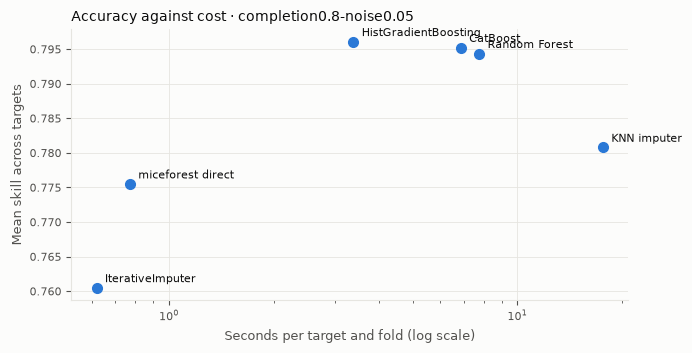

,method,warning_types,tasks,warning_example
0,IterativeImputer,ConvergenceWarning,140,[IterativeImputer] Early stopping criterion not reached.
1,IterativeImputer (5),ConvergenceWarning,5,[IterativeImputer] Early stopping criterion not reached.
2,IterativeImputer (30),ConvergenceWarning,5,[IterativeImputer] Early stopping criterion not reached.


In [41]:
display(STUDY.cost.round(3))
fg.plot_cost(STUDY.cost, NUMERIC, REPRESENTATIVE, FIGURES)
with pd.option_context("display.max_colwidth", None):
    display(ev.warning_table(STUDY.log))

### A.4 Saved results

The last cell writes one completed table per method to the run folder and summarises the run. Every table of chapters 5 to 9 is also saved there as a CSV file.

In [42]:
completed = ev.export_completions(SCORED, STUDY.measured[REPRESENTATIVE], REPRESENTATIVE, Path(STUDY.directory) / "completed")
display(completed)
display(ev.run_summary(STUDY.log, STUDY.plan))
print("Run folder:", STUDY.directory)
print("To repeat the evaluation, set EVALUATION_RUN_ID to:", Path(STUDY.directory).name)

,method,file,cells still missing
0,Median,Median.csv,0
1,KNN imputer,KNN_imputer.csv,0
2,IterativeImputer,IterativeImputer.csv,1965
3,Random Forest,Random_Forest.csv,0
4,HistGradientBoosting,HistGradientBoosting.csv,0
5,CatBoost,CatBoost.csv,0
6,miceforest direct,miceforest_direct.csv,0


,planned tasks,finished tasks,succeeded,failed,tasks with warnings
0,2230,2230,2230,0,150


Run folder: C:\Users\Morgan\Desktop\Capstone Project\gh\team19-asset-data\outputs\imputation-study\runs\20261114-114941
To repeat the evaluation, set EVALUATION_RUN_ID to: 20261114-114941
